# Step 6 – Clustering Analysis

This step identifies distinct borrower segments using three algorithms:

1. K-Means – partitions borrowers into a predefined number of segments.
2. Hierarchical Clustering – builds a hierarchy of borrower groups.
3. DBSCAN – identifies dense borrower groups and detects potential outliers.

The dataset contains 1,347,681 records, so computational requirements are handled carefully: the 10-component PCA representation is used instead of the original 34-feature matrix, and the algorithms are run on a reproducible 5,000-record sample.

**Structure of this notebook**

- 6.1–6.5: initial runs of the three algorithms and their comparison.
- 6.6: re-run on standardized PCA components, with the final comparison.
- 6.7: report-ready summary.
- Step 7: cluster evaluation, profiling and stability validation.

## 6.1 Prepare the clustering dataset

For a fair initial comparison, the same reproducible sample of 5,000 borrowers is used for all three algorithms. This keeps hierarchical clustering and DBSCAN computationally manageable

In [2]:
import pandas as pd
from pathlib import Path

DATA_PATH = Path(
    r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\Pickle\cleaned_credit_portfolio.pkl"
)

df = pd.read_pickle(DATA_PATH)      # not read_csv

print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (1347681, 15)


,id,issue_d,revenue,dti_n,loan_amnt,fico_n,experience_c,emp_length,purpose,home_ownership_n,addr_state,Default,revenue_log,dti_capped,dti_extreme
0,68407277,Dec-2015,55000.0,5.91,3600,677.0,1,10+ years,debt_consolidation,MORTGAGE,PA,0,10.915107,5.91,0
1,68355089,Dec-2015,65000.0,16.06,24700,717.0,1,10+ years,small_business,MORTGAGE,SD,0,11.082158,16.06,0
2,68341763,Dec-2015,71000.0,13.85,20000,697.0,1,10+ years,home_improvement,MORTGAGE,IL,0,11.170449,13.85,0
3,68476807,Dec-2015,104433.0,25.37,10400,697.0,1,3 years,major_purchase,MORTGAGE,PA,0,11.556311,25.37,0
4,68426831,Dec-2015,34000.0,10.20,11950,692.0,1,4 years,debt_consolidation,RENT,GA,0,10.434145,10.20,0


In [3]:
import numpy as np
import pandas as pd

# Select numerical features
numerical_features = [
    'revenue_log',
    'loan_amnt_log',
    'fico_n',
    'dti_capped'
]

# Select categorical features
categorical_features = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

# Recreate loan amount log if it is missing
if 'loan_amnt_log' not in df.columns:
    df['loan_amnt_log'] = np.log1p(df['loan_amnt'])

# Check required columns
required_columns = numerical_features + categorical_features

print("Missing columns:", [
    col for col in required_columns if col not in df.columns
])

Missing columns: []


In [4]:
# Create clustering dataset
cluster_df = df[required_columns].copy()

print("Clustering dataset shape:", cluster_df.shape)
print("\nData types:")
print(cluster_df.dtypes)

print("\nMissing values:")
print(cluster_df.isnull().sum())

Clustering dataset shape: (1347681, 7)

Data types:
revenue_log         float64
loan_amnt_log       float64
fico_n              float64
dti_capped          float64
emp_length              str
purpose                 str
home_ownership_n        str
dtype: object

Missing values:
revenue_log         0
loan_amnt_log       0
fico_n              0
dti_capped          0
emp_length          0
purpose             0
home_ownership_n    0
dtype: int64


### 6.1.2 Rebuild encoding and scaling

The following are used:

- StandardScaler for numerical features.
- OneHotEncoder for categorical features.
- ColumnTransformer to combine both transformations.

In [5]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Define feature groups
numerical_features = [
    'revenue_log',
    'loan_amnt_log',
    'fico_n',
    'dti_capped'
]

categorical_features = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

# Create preprocessing pipeline
preprocessor = ColumnTransformer(
    transformers=[
        ('num', StandardScaler(), numerical_features),
        ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_features)
    ],
    remainder='drop',
    sparse_threshold=1.0
)

# Fit and transform
X_cluster_scaled = preprocessor.fit_transform(cluster_df)

print("Original clustering data shape:", cluster_df.shape)
print("Transformed feature matrix shape:", X_cluster_scaled.shape)
print("Matrix type:", type(X_cluster_scaled))

print("\nNumerical features:", numerical_features)
print("Categorical features:", categorical_features)

Original clustering data shape: (1347681, 7)
Transformed feature matrix shape: (1347681, 34)
Matrix type: <class 'scipy.sparse._csr.csr_matrix'>

Numerical features: ['revenue_log', 'loan_amnt_log', 'fico_n', 'dti_capped']
Categorical features: ['emp_length', 'purpose', 'home_ownership_n']


### 6.1.3 Verify scaling and encoding

In [6]:
print("Number of transformed features:",
      len(preprocessor.get_feature_names_out()))

print("\nMissing values in transformed matrix:",
      np.isnan(X_cluster_scaled.data).sum()
      if hasattr(X_cluster_scaled, "data")
      else np.isnan(X_cluster_scaled).sum())

Number of transformed features: 34

Missing values in transformed matrix: 0


### 6.1.4 Recreate PCA

In [7]:
from sklearn.decomposition import IncrementalPCA
import numpy as np

n_samples = X_cluster_scaled.shape[0]
batch_size = 50000
n_components = 10

ipca = IncrementalPCA(
    n_components=n_components,
    batch_size=batch_size
)

# Fit PCA incrementally
for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)

    batch = X_cluster_scaled[start:end].toarray()
    ipca.partial_fit(batch)

# Transform the complete dataset
X_pca = np.empty(
    (n_samples, n_components),
    dtype=np.float32
)

for start in range(0, n_samples, batch_size):
    end = min(start + batch_size, n_samples)

    batch = X_cluster_scaled[start:end].toarray()
    X_pca[start:end] = ipca.transform(batch)

print("Original shape:", X_cluster_scaled.shape)
print("PCA shape:", X_pca.shape)

print("\nTotal explained variance:",
      round(ipca.explained_variance_ratio_.sum() * 100, 2), "%")

Original shape: (1347681, 34)
PCA shape: (1347681, 10)

Total explained variance: 88.95 %


### 6.1.5 Prepare a representative sample

In [8]:
import numpy as np
import pandas as pd

# Reproducible random sampling
rng = np.random.default_rng(42)

sample_size = 5000

sample_indices = rng.choice(
    X_pca.shape[0],
    size=sample_size,
    replace=False
)

# PCA sample for clustering
X_cluster_sample = X_pca[sample_indices]

# Default labels reserved for post-clustering interpretation
default_sample = (
    df.iloc[sample_indices]['Default'].to_numpy()
)

print("Full PCA shape:", X_pca.shape)
print("Clustering sample shape:", X_cluster_sample.shape)

print("\nDefault distribution in sample:")
print(pd.Series(default_sample).value_counts().sort_index())

print("\nMissing values:",
      np.isnan(X_cluster_sample).sum())

Full PCA shape: (1347681, 10)
Clustering sample shape: (5000, 10)

Default distribution in sample:
0    3963
1    1037
Name: count, dtype: int64

Missing values: 0


## 6.2 K-Means clustering (initial run on the PCA sample)

In [9]:
import matplotlib.pyplot as plt
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

k_values = range(2, 9)

inertia_values = []
silhouette_values = []

for k in k_values:

    kmeans = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    cluster_labels = kmeans.fit_predict(X_cluster_sample)

    inertia_values.append(kmeans.inertia_)

    score = silhouette_score(
        X_cluster_sample,
        cluster_labels,
        sample_size=2000,
        random_state=42
    )

    silhouette_values.append(score)

    print(
        f"K={k} | "
        f"Inertia={kmeans.inertia_:.2f} | "
        f"Silhouette Score={score:.4f}"
    )

K=2 | Inertia=21942.64 | Silhouette Score=0.1699
K=3 | Inertia=19406.88 | Silhouette Score=0.1653
K=4 | Inertia=17380.73 | Silhouette Score=0.1478
K=5 | Inertia=16216.11 | Silhouette Score=0.1334
K=6 | Inertia=15419.57 | Silhouette Score=0.1252
K=7 | Inertia=14766.64 | Silhouette Score=0.1244
K=8 | Inertia=14243.53 | Silhouette Score=0.1236


### 6.2.1 Elbow method

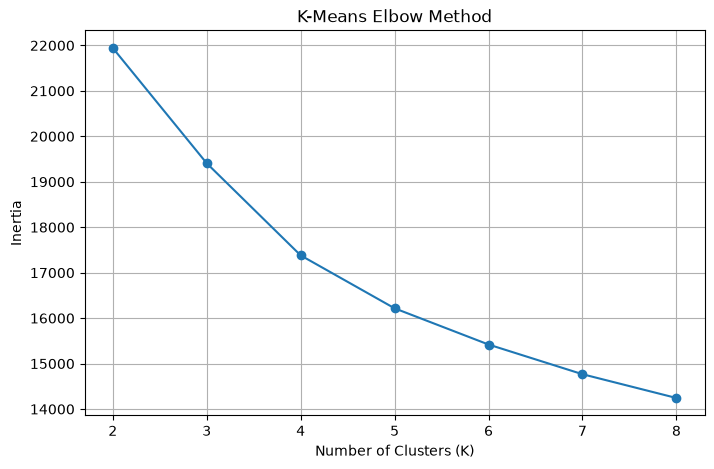

In [10]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    inertia_values,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Inertia")
plt.title("K-Means Elbow Method")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 6.2.2 Silhouette scores

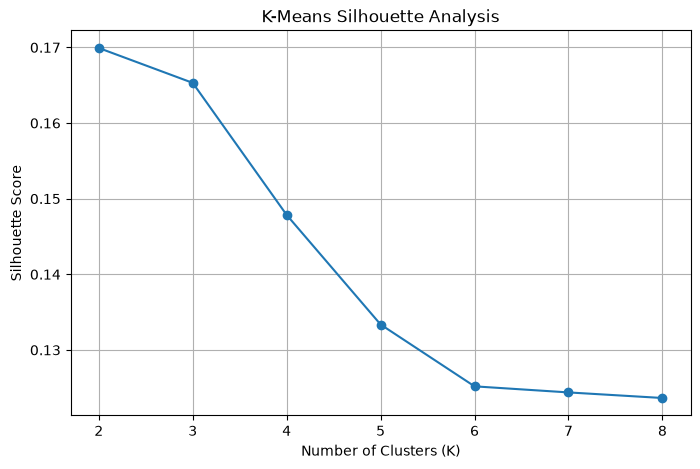

In [11]:
plt.figure(figsize=(8, 5))

plt.plot(
    list(k_values),
    silhouette_values,
    marker='o'
)

plt.xlabel("Number of Clusters (K)")
plt.ylabel("Silhouette Score")
plt.title("K-Means Silhouette Analysis")
plt.xticks(list(k_values))
plt.grid(True)
plt.show()

### 6.2.3 Comparison table

In [12]:
kmeans_results = pd.DataFrame({
    'K': list(k_values),
    'Inertia': inertia_values,
    'Silhouette_Score': silhouette_values
})

print(kmeans_results)

   K       Inertia  Silhouette_Score
0  2  21942.636719          0.169922
1  3  19406.876953          0.165309
2  4  17380.732422          0.147847
3  5  16216.112305          0.133363
4  6  15419.573242          0.125187
5  7  14766.638672          0.124383
6  8  14243.531250          0.123646


### 6.2.4 Interpretation of K-Means results

| K | Inertia | Silhouette score |
|---|---|---|
| 2 | 21,942.64 | 0.1699 |
| 3 | 19,406.88 | 0.1653 |
| 4 | 17,380.73 | 0.1478 |
| 5 | 16,216.11 | 0.1334 |
| 6 | 15,419.57 | 0.1252 |
| 7 | 14,766.64 | 0.1244 |
| 8 | 14,243.53 | 0.1236 |

Interpretation:

1. K=2 has the highest silhouette score (0.1699).
2. Silhouette scores decline as K increases, suggesting that adding more clusters does not improve separation.
3. Inertia decreases as K increases, which is expected. Its reduction becomes progressively smaller.
4. The silhouette scores are relatively low, indicating that borrower groups overlap considerably in the PCA feature space.

Initial selection: K=2. This is the strongest choice based on the silhouette results, although the separation is weak. It should not be claimed that two naturally distinct borrower segments have been established.

### 6.2.5 Fit the final K-Means model (K=2)

In [13]:
from sklearn.cluster import KMeans

# Final K-Means model
kmeans_final = KMeans(
    n_clusters=2,
    random_state=42,
    n_init=10
)

kmeans_labels = kmeans_final.fit_predict(X_cluster_sample)

# Create analysis dataframe
kmeans_analysis = cluster_df.iloc[sample_indices].copy()

kmeans_analysis['Cluster'] = kmeans_labels
kmeans_analysis['Default'] = default_sample

print("K-Means clustering completed.")

print("\nCluster distribution:")
print(kmeans_analysis['Cluster'].value_counts().sort_index())

K-Means clustering completed.

Cluster distribution:
Cluster
0    2429
1    2571
Name: count, dtype: int64


### 6.2.6 Analyze borrower segments

In [14]:
# Cluster size and percentage
cluster_summary = (
    kmeans_analysis.groupby('Cluster')
    .agg(
        Total_Borrowers=('Default', 'count'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean'),
        Average_Revenue=('revenue_log', 'mean'),
        Average_Loan_Amount=('loan_amnt_log', 'mean'),
        Average_FICO=('fico_n', 'mean'),
        Average_DTI=('dti_capped', 'mean')
    )
)

cluster_summary['Default_Rate'] *= 100

cluster_summary['Percentage_of_Borrowers'] = (
    cluster_summary['Total_Borrowers'] /
    len(kmeans_analysis) * 100
)

print(cluster_summary.round(2))

         Total_Borrowers  Default_Count  Default_Rate  Average_Revenue  \
Cluster                                                                  
0                   2429            537         22.11            10.74   
1                   2571            500         19.45            11.44   

         Average_Loan_Amount  Average_FICO  Average_DTI  \
Cluster                                                   
0                       8.90        689.00        20.17   
1                       9.82        706.32        16.49   

         Percentage_of_Borrowers  
Cluster                           
0                          48.58  
1                          51.42  


### 6.2.7 Compare default distribution

Default      0      1
Cluster              
0        77.89  22.11
1        80.55  19.45


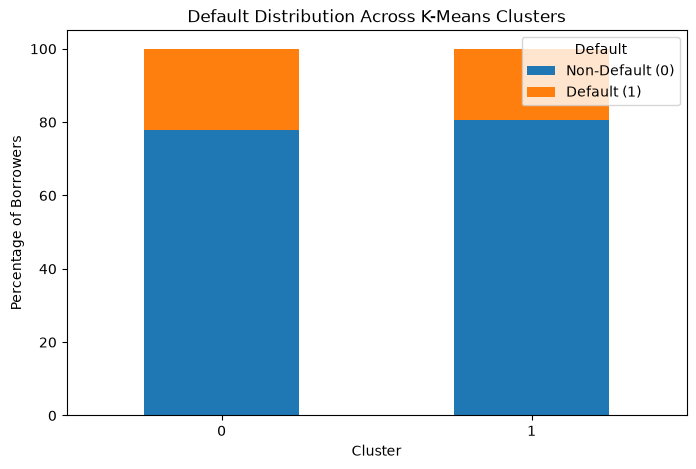

In [15]:
import seaborn as sns
import matplotlib.pyplot as plt

default_comparison = pd.crosstab(
    kmeans_analysis['Cluster'],
    kmeans_analysis['Default'],
    normalize='index'
) * 100

print(default_comparison.round(2))

default_comparison.plot(
    kind='bar',
    stacked=True,
    figsize=(8, 5)
)

plt.title("Default Distribution Across K-Means Clusters")
plt.xlabel("Cluster")
plt.ylabel("Percentage of Borrowers")
plt.legend(
    title="Default",
    labels=["Non-Default (0)", "Default (1)"]
)
plt.xticks(rotation=0)
plt.show()

### 6.2.8 K-Means (K=2) results

The K-Means model identified two borrower segments among 5,000 sampled borrowers.

#### 1. Cluster distribution

| Cluster | Borrowers | Portfolio share |
|---|---|---|
| Cluster 0 | 2,429 | 48.58% |
| Cluster 1 | 2,571 | 51.42% |
| Total | 5,000 | 100% |

#### 2. Borrower segment analysis

| Metric | Cluster 0 | Cluster 1 |
|---|---|---|
| Default count | 537 | 500 |
| Default rate | 22.11% | 19.45% |
| Average revenue (log) | 10.74 | 11.44 |
| Average loan amount (log) | 8.90 | 9.82 |
| Average FICO | 689.00 | 706.32 |
| Average DTI | 20.17 | 16.49 |

#### 3. Interpretation

Cluster 0 – Relatively higher-risk segment

- Lower average revenue.
- Lower average FICO score.
- Higher average DTI.
- Higher default rate (22.11%).

Cluster 1 – Relatively lower-risk segment

- Higher average revenue.
- Higher average FICO score.
- Lower average DTI.
- Lower default rate (19.45%).

Default-rate comparison: Cluster 0 = 22.11%; Cluster 1 = 19.45%.

Cluster 0 has a 2.66 percentage-point higher observed default rate.

Important observation: The two segments differ in their average financial characteristics, but their default rates are relatively close. This is consistent with the relatively low silhouette score (0.1699). Therefore, these are preliminary borrower profiles, not strongly separated risk categories.

#### 4. Portfolio-ready conclusion

K-Means clustering with K=2 identified two borrower segments. Cluster 0 demonstrated relatively higher financial risk characteristics, including lower FICO scores, lower revenue and higher DTI. Its observed default rate was 22.11%, compared with 19.45% in Cluster 1. However, the low silhouette score indicates considerable overlap between the segments.

## 6.3 Hierarchical clustering (initial run)

The same 5,000-borrower PCA sample is used. Hierarchical clustering with Ward linkage is tested for 2 to 5 clusters.

In [16]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hierarchical_results = []

for k in range(2, 6):

    hc = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = hc.fit_predict(X_cluster_sample)

    score = silhouette_score(
        X_cluster_sample,
        labels,
        sample_size=2000,
        random_state=42
    )

    hierarchical_results.append({
        'K': k,
        'Silhouette_Score': score
    })

    print(f"K={k}, Silhouette Score={score:.4f}")

hierarchical_results_df = pd.DataFrame(hierarchical_results)

print("\nHierarchical Clustering Results:")
print(hierarchical_results_df)

K=2, Silhouette Score=0.1489
K=3, Silhouette Score=0.1251
K=4, Silhouette Score=0.0872
K=5, Silhouette Score=0.0701

Hierarchical Clustering Results:
   K  Silhouette_Score
0  2          0.148929
1  3          0.125052
2  4          0.087222
3  5          0.070090


### 6.3.1 Interpretation of the silhouette scores

- K=2 provides the best separation among the tested cluster counts.
- Silhouette scores decrease as the number of clusters increases.
- The scores are relatively low, indicating substantial overlap between borrower segments.
- Compared with K-Means (0.1699), Hierarchical Clustering (0.1489) produces slightly weaker separation.

### 6.3.2 Fit the final hierarchical model

K=2 is selected based on the evaluation.

In [17]:
from sklearn.cluster import AgglomerativeClustering

# Final Hierarchical Clustering model
hc_final = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

hc_labels = hc_final.fit_predict(X_cluster_sample)

# Create analysis dataframe
hc_analysis = cluster_df.iloc[sample_indices].copy()

hc_analysis['Cluster'] = hc_labels
hc_analysis['Default'] = default_sample

print("Hierarchical clustering completed.")

print("\nCluster distribution:")
print(hc_analysis['Cluster'].value_counts().sort_index())

Hierarchical clustering completed.

Cluster distribution:
Cluster
0    4058
1     942
Name: count, dtype: int64


### 6.3.3 Analyze borrower segments

In [18]:
hc_summary = (
    hc_analysis.groupby('Cluster')
    .agg(
        Total_Borrowers=('Default', 'count'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean'),
        Average_Revenue=('revenue_log', 'mean'),
        Average_Loan_Amount=('loan_amnt_log', 'mean'),
        Average_FICO=('fico_n', 'mean'),
        Average_DTI=('dti_capped', 'mean')
    )
)

hc_summary['Default_Rate'] *= 100

hc_summary['Percentage_of_Borrowers'] = (
    hc_summary['Total_Borrowers'] /
    len(hc_analysis) * 100
)

print(hc_summary.round(2))

         Total_Borrowers  Default_Count  Default_Rate  Average_Revenue  \
Cluster                                                                  
0                   4058            791         19.49            11.21   
1                    942            246         26.11            10.63   

         Average_Loan_Amount  Average_FICO  Average_DTI  \
Cluster                                                   
0                       9.54        700.78        17.09   
1                       8.67        685.51        23.40   

         Percentage_of_Borrowers  
Cluster                           
0                          81.16  
1                          18.84  


### 6.3.4 Compare default distribution

In [19]:
hc_default_comparison = pd.crosstab(
    hc_analysis['Cluster'],
    hc_analysis['Default'],
    normalize='index'
) * 100

print(hc_default_comparison.round(2))

Default      0      1
Cluster              
0        80.51  19.49
1        73.89  26.11


### 6.3.5 Hierarchical (K=2) results

The hierarchical model identified two borrower segments with noticeably different portfolio characteristics.

#### 1. Cluster distribution

| Cluster | Borrowers | Portfolio share |
|---|---|---|
| Cluster 0 | 4,058 | 81.16% |
| Cluster 1 | 942 | 18.84% |
| Total | 5,000 | 100% |

#### 2. Borrower segment analysis

| Metric | Cluster 0 | Cluster 1 |
|---|---|---|
| Default count | 791 | 246 |
| Default rate | 19.49% | 26.11% |
| Average revenue (log) | 11.21 | 10.63 |
| Average loan amount (log) | 9.54 | 8.67 |
| Average FICO | 700.78 | 685.51 |
| Average DTI | 17.09 | 23.40 |

#### 3. Interpretation

Cluster 0 – Relatively lower-risk segment

- Contains 81.16% of sampled borrowers.
- Higher average FICO score.
- Higher average revenue.
- Lower average DTI.
- Default rate: 19.49%.

Cluster 1 – Relatively higher-risk segment

- Contains 18.84% of sampled borrowers.
- Lower average FICO score.
- Lower average revenue.
- Higher average DTI.
- Default rate: 26.11%.

The difference in observed default rates is 6.62 percentage points.

This is a useful segmentation result: Hierarchical Clustering identified a smaller group with comparatively weaker financial characteristics and a higher observed default rate.

## 6.4 DBSCAN clustering (initial run)

DBSCAN identifies dense borrower groups and detects unusual observations as noise points (outliers). Unlike K-Means and Hierarchical Clustering, it does not require the number of clusters to be specified in advance. The PCA sample is standardized before DBSCAN (Section 6.4.1).

### 6.4.1 Prepare PCA data for DBSCAN

In [20]:
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
import numpy as np
import matplotlib.pyplot as plt

# Standardize PCA sample for DBSCAN
dbscan_scaler = StandardScaler()

X_dbscan = dbscan_scaler.fit_transform(X_cluster_sample)

print("DBSCAN input shape:", X_dbscan.shape)
print("Missing values:", np.isnan(X_dbscan).sum())

DBSCAN input shape: (5000, 10)
Missing values: 0


### 6.4.2 Find a suitable epsilon (eps)

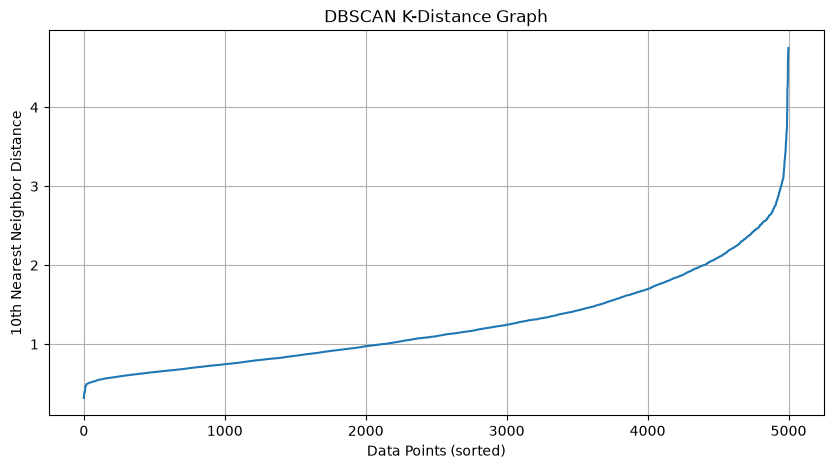

K-distance percentiles:
50th percentile: 1.1001
75th percentile: 1.5536
85th percentile: 1.8775
90th percentile: 2.0967
95th percentile: 2.4230
97th percentile: 2.5919
99th percentile: 3.0139


In [21]:
# Find 10 nearest neighbors
neighbors = NearestNeighbors(n_neighbors=10)

neighbors.fit(X_dbscan)

distances, indices = neighbors.kneighbors(X_dbscan)

# Sort distances to the 10th nearest neighbor
k_distances = np.sort(distances[:, -1])

# Plot k-distance graph
plt.figure(figsize=(10, 5))

plt.plot(k_distances)

plt.xlabel("Data Points (sorted)")
plt.ylabel("10th Nearest Neighbor Distance")
plt.title("DBSCAN K-Distance Graph")
plt.grid(True)

plt.show()

# Print distance percentiles
print("K-distance percentiles:")

for p in [50, 75, 85, 90, 95, 97, 99]:
    print(f"{p}th percentile: {np.percentile(k_distances, p):.4f}")

### 6.4.3 Interpret epsilon (eps)

| Percentile | Distance |
|---|---|
| 50th | 1.1001 |
| 75th | 1.5536 |
| 85th | 1.8775 |
| 90th | 2.0967 |
| 95th | 2.4230 |
| 97th | 2.5919 |
| 99th | 3.0139 |

For the initial DBSCAN experiments, eps values of about 1.5–2.6 are tested with min_samples=10.

These are candidate values, not a confirmed optimum. The number of clusters, noise percentage and silhouette score (where valid) are compared.

### 6.4.4 Test DBSCAN parameter combinations

In [23]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import pandas as pd
import numpy as np

eps_values = [1.5, 1.8, 2.1, 2.4, 2.6]
min_samples = 10

dbscan_results = []

for eps in eps_values:

    dbscan_model = DBSCAN(
        eps=eps,
        min_samples=min_samples,
        metric='euclidean',
        n_jobs=-1
    )

    labels = dbscan_model.fit_predict(X_dbscan)

    # Count clusters, excluding noise (-1)
    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})

    # Count noise observations
    noise_count = np.sum(labels == -1)
    noise_percentage = noise_count / len(labels) * 100

    # Calculate silhouette only when valid
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]

    if (
        n_clusters >= 2
        and len(valid_labels) > n_clusters
    ):
        score = silhouette_score(
            X_dbscan[valid_mask],
            valid_labels,
            sample_size=min(2000, len(valid_labels)),
            random_state=42
        )
    else:
        score = np.nan

    dbscan_results.append({
        'Epsilon': eps,
        'Min_Samples': min_samples,
        'Number_of_Clusters': n_clusters,
        'Noise_Count': noise_count,
        'Noise_Percentage': noise_percentage,
        'Silhouette_Score': score
    })

    print(
        f"eps={eps} | "
        f"Clusters={n_clusters} | "
        f"Noise={noise_count} ({noise_percentage:.2f}%) | "
        f"Silhouette={score}"
    )

dbscan_results_df = pd.DataFrame(dbscan_results)

print("\nDBSCAN Parameter Comparison:")
print(dbscan_results_df.round(4))

eps=1.5 | Clusters=25 | Noise=704 (14.08%) | Silhouette=0.2525942325592041
eps=1.8 | Clusters=30 | Noise=367 (7.34%) | Silhouette=0.24150528013706207
eps=2.1 | Clusters=20 | Noise=130 (2.60%) | Silhouette=0.0954514741897583
eps=2.4 | Clusters=2 | Noise=63 (1.26%) | Silhouette=0.1915542334318161
eps=2.6 | Clusters=1 | Noise=34 (0.68%) | Silhouette=nan

DBSCAN Parameter Comparison:
   Epsilon  Min_Samples  Number_of_Clusters  Noise_Count  Noise_Percentage  \
0      1.5           10                  25          704             14.08   
1      1.8           10                  30          367              7.34   
2      2.1           10                  20          130              2.60   
3      2.4           10                   2           63              1.26   
4      2.6           10                   1           34              0.68   

   Silhouette_Score  
0            0.2526  
1            0.2415  
2            0.0955  
3            0.1916  
4               NaN  


### 6.4.5 Interpret DBSCAN results

| Epsilon | Clusters | Noise | Noise % | Silhouette |
|---|---|---|---|---|
| 1.5 | 25 | 704 | 14.08% | 0.2526 |
| 1.8 | 30 | 367 | 7.34% | 0.2415 |
| 2.1 | 20 | 130 | 2.60% | 0.0955 |
| 2.4 | 2 | 63 | 1.26% | 0.1916 |
| 2.6 | 1 | 34 | 0.68% | Not defined |

Interpretation

- eps=1.5: Highest silhouette score, but it creates 25 clusters and labels 14.08% of borrowers as noise.
- eps=1.8: Creates 30 clusters, so it may over-segment the borrower population.
- eps=2.1: Produces 20 clusters, with a much lower silhouette score.
- eps=2.4: Produces one dominant cluster (98.5% of the sample), a 12-borrower cluster and only 1.26% noise.
- eps=2.6: Produces only one cluster, so silhouette comparison is not possible.

Candidate configuration: eps=2.4, min_samples=10

eps=2.4 has a small noise group (1.26%), but it does not produce two broad segments: one cluster holds 98.5% of the sample and the second contains only 12 borrowers (Section 6.4.7). It is used here only as the least fragmented configuration, not as a meaningful segmentation. The more detailed eps=1.5 and eps=1.8 configurations are profiled in Section 6.6.7.

### 6.4.6 Fit the final DBSCAN model

In [24]:
from sklearn.cluster import DBSCAN

# Final DBSCAN model
dbscan_final = DBSCAN(
    eps=2.4,
    min_samples=10,
    metric='euclidean',
    n_jobs=-1
)

dbscan_labels = dbscan_final.fit_predict(X_dbscan)

# Create analysis dataframe
dbscan_analysis = cluster_df.iloc[sample_indices].copy()

dbscan_analysis['Cluster'] = dbscan_labels
dbscan_analysis['Default'] = default_sample

# Cluster distribution
print("DBSCAN clustering completed.")

print("\nCluster distribution:")
print(dbscan_analysis['Cluster'].value_counts().sort_index())

print("\nNoise observations:",
      (dbscan_labels == -1).sum())

DBSCAN clustering completed.

Cluster distribution:
Cluster
-1      63
 0    4925
 1      12
Name: count, dtype: int64

Noise observations: 63


### 6.4.7 Analyze borrower segments

Note: DBSCAN assigns -1 to noise observations; they are kept as a separate group in the analysis.

In [25]:
dbscan_summary = (
    dbscan_analysis.groupby('Cluster')
    .agg(
        Total_Borrowers=('Default', 'count'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean'),
        Average_Revenue=('revenue_log', 'mean'),
        Average_Loan_Amount=('loan_amnt_log', 'mean'),
        Average_FICO=('fico_n', 'mean'),
        Average_DTI=('dti_capped', 'mean')
    )
)

dbscan_summary['Default_Rate'] *= 100

dbscan_summary['Percentage_of_Borrowers'] = (
    dbscan_summary['Total_Borrowers'] /
    len(dbscan_analysis) * 100
)

print(dbscan_summary.round(2))

         Total_Borrowers  Default_Count  Default_Rate  Average_Revenue  \
Cluster                                                                  
-1                    63             12         19.05            11.39   
 0                  4925           1023         20.77            11.10   
 1                    12              2         16.67            10.79   

         Average_Loan_Amount  Average_FICO  Average_DTI  \
Cluster                                                   
-1                      9.24        736.05        22.25   
 0                      9.38        697.42        18.22   
 1                      9.19        694.92        21.12   

         Percentage_of_Borrowers  
Cluster                           
-1                          1.26  
 0                         98.50  
 1                          0.24  


### 6.4.8 Compare default distribution

In [26]:
dbscan_default_comparison = pd.crosstab(
    dbscan_analysis['Cluster'],
    dbscan_analysis['Default'],
    normalize='index'
) * 100

print(dbscan_default_comparison.round(2))

Default      0      1
Cluster              
-1       80.95  19.05
 0       79.23  20.77
 1       83.33  16.67


### 6.4.9 DBSCAN (eps=2.4) results

The DBSCAN model identified one dominant dense group (Cluster 0), a very small second group (Cluster 1, 12 borrowers) and a small number of noise observations.

#### 1. DBSCAN cluster distribution

| Cluster | Borrowers | Portfolio share |
|---|---|---|
| Noise (-1) | 63 | 1.26% |
| Cluster 0 | 4,925 | 98.50% |
| Cluster 1 | 12 | 0.24% |
| Total | 5,000 | 100% |

#### 2. Borrower segment analysis

| Metric | Noise (-1) | Cluster 0 | Cluster 1 |
|---|---|---|---|
| Default count | 12 | 1,023 | 2 |
| Default rate | 19.05% | 20.77% | 16.67% |
| Average revenue (log) | 11.39 | 11.10 | 10.79 |
| Average loan amount (log) | 9.24 | 9.38 | 9.19 |
| Average FICO | 736.05 | 697.42 | 694.92 |
| Average DTI | 22.25 | 18.22 | 21.12 |

#### 3. Interpretation

- Cluster 0: Contains 98.50% of borrowers. It represents the dominant density-based group.
- Cluster 1: Contains only 12 borrowers (0.24%). This is too small to consider a meaningful general borrower segment without further validation.
- Noise: Contains 63 borrowers (1.26%) that DBSCAN did not assign to a cluster. These are not necessarily bad borrowers or credit defaults.

## 6.5 Comparison of the initial runs

### 6.5.1 Model performance comparison

| Evaluation metric | K-Means | Hierarchical | DBSCAN |
|---|---|---|---|
| Parameters | K=2 | K=2, Ward | eps=2.4, min_samples=10 |
| Clusters detected | 2 | 2 | 2 |
| Silhouette score | 0.1699 | 0.1489 | 0.1916 |
| Noise observations | Not applicable | Not applicable | 63 (1.26%) |
| Largest cluster | 51.42% | 81.16% | 98.50% |
| Smallest cluster | 48.58% | 18.84% | 0.24% |

The silhouette scores are provisional and not strictly comparable because DBSCAN used standardized PCA coordinates, whereas K-Means and Hierarchical Clustering used unstandardized PCA coordinates.

### 6.5.2 Default-risk comparison

| Algorithm | Segment | Default rate |
|---|---|---|
| K-Means | Cluster 0 | 22.11% |
| K-Means | Cluster 1 | 19.45% |
| Hierarchical | Cluster 0 | 19.49% |
| Hierarchical | Cluster 1 | 26.11% |
| DBSCAN | Cluster 0 | 20.77% |
| DBSCAN | Cluster 1 | 16.67% |
| DBSCAN | Noise | 19.05% |

### 6.5.3 Overall interpretation

K-Means

- Produces two reasonably balanced borrower segments.
- Cluster 0 has a higher observed default rate.
- Easy to interpret and useful as a baseline segmentation method.

Hierarchical Clustering

- Produces one large and one smaller segment.
- The smaller segment has a 26.11% default rate.
- Identifies the largest default-rate difference among the two-cluster results.

DBSCAN

- Identifies a dominant group and a small secondary group.
- Detects 63 noise observations.
- Does not produce useful broad segmentation with the tested parameters.

### 6.5.4 Methodological improvement: standardized PCA

For a fair comparison, all three algorithms should use the same standardized PCA representation (done in Section 6.6; DBSCAN already used standardized PCA). This is important because PCA components have different variances, and distance-based algorithms can be affected by those differences.

Also, the DBSCAN secondary cluster contains only 12 borrowers, so its 16.67% default rate should not be treated as a reliable risk estimate.

### 6.5.5 Portfolio-ready conclusion

The initial experiments suggest that K-Means and Hierarchical Clustering provide more interpretable borrower segmentation than the tested DBSCAN configuration. Hierarchical Clustering identified a smaller segment with a higher observed default rate of 26.11%, while K-Means produced more balanced segments with relatively modest differences in default rates. DBSCAN identified a dominant dense group and 63 noise observations but did not provide meaningful broad segmentation.

These findings are exploratory. They do not establish causal relationships or prove that the identified segments predict future defaults.

Recommendation: keep all three algorithms in the project, document their limitations, and use the standardized-PCA comparison in Section 6.6 as the final model comparison.

## 6.6 Re-run on standardized PCA

PCA components have different variances, so K-Means and hierarchical clustering are re-run on the standardized PCA sample (DBSCAN already used it).

Note: standardizing PCA scores gives every component equal weight, including low-variance components (PC10 explains only 1.4% of the variance). This changes the geometry of the data, so results should be compared with the unstandardized runs in Sections 6.2 and 6.3.

### 6.6.1 Standardize the PCA sample

In [27]:
from sklearn.preprocessing import StandardScaler
import numpy as np
import pandas as pd

# Standardize the 10 PCA components
pca_scaler = StandardScaler()

X_cluster_std = pca_scaler.fit_transform(X_cluster_sample)

print("Standardized PCA shape:", X_cluster_std.shape)
print("Missing values:", np.isnan(X_cluster_std).sum())

print("\nMean of first 5 components:")
print(np.round(X_cluster_std.mean(axis=0)[:5], 4))

print("\nStandard deviation of first 5 components:")
print(np.round(X_cluster_std.std(axis=0)[:5], 4))

Standardized PCA shape: (5000, 10)
Missing values: 0

Mean of first 5 components:
[ 0.  0.  0.  0. -0.]

Standard deviation of first 5 components:
[1. 1. 1. 1. 1.]


### 6.6.2 Re-evaluate K-Means

In [28]:
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

kmeans_results_std = []

for k in range(2, 9):
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )

    labels = model.fit_predict(X_cluster_std)

    score = silhouette_score(
        X_cluster_std,
        labels,
        sample_size=2000,
        random_state=42
    )

    kmeans_results_std.append({
        'K': k,
        'Inertia': round(model.inertia_, 2),
        'Silhouette_Score': round(score, 4)
    })

kmeans_results_std = pd.DataFrame(kmeans_results_std)

print(kmeans_results_std)

   K   Inertia  Silhouette_Score
0  2  44962.68            0.1130
1  3  40105.34            0.1494
2  4  36750.58            0.1622
3  5  34492.54            0.1522
4  6  32216.40            0.1498
5  7  30083.48            0.1540
6  8  28746.22            0.1538


### 6.6.3 Hierarchical clustering on standardized PCA

In [29]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score

hc_results_std = []

for k in range(2, 9):

    model = AgglomerativeClustering(
        n_clusters=k,
        linkage='ward'
    )

    labels = model.fit_predict(X_cluster_std)

    score = silhouette_score(
        X_cluster_std,
        labels,
        sample_size=2000,
        random_state=42
    )

    hc_results_std.append({
        'K': k,
        'Silhouette_Score': round(score, 4)
    })

hc_results_std = pd.DataFrame(hc_results_std)

print(hc_results_std)

   K  Silhouette_Score
0  2            0.2177
1  3            0.1388
2  4            0.1497
3  5            0.1646
4  6            0.1453
5  7            0.1480
6  8            0.1611


### 6.6.4 Fit final models and compare borrower segments

In [30]:
# ==========================================
# FINAL K-MEANS MODEL (K=4)
# ==========================================

kmeans_final_std = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

kmeans_labels_std = kmeans_final_std.fit_predict(X_cluster_std)


# ==========================================
# FINAL HIERARCHICAL MODEL (K=2)
# ==========================================

hc_final_std = AgglomerativeClustering(
    n_clusters=2,
    linkage='ward'
)

hc_labels_std = hc_final_std.fit_predict(X_cluster_std)


# ==========================================
# CREATE ANALYSIS DATAFRAMES
# ==========================================

kmeans_analysis_std = cluster_df.iloc[sample_indices].copy()
kmeans_analysis_std['Cluster'] = kmeans_labels_std
kmeans_analysis_std['Default'] = default_sample

hc_analysis_std = cluster_df.iloc[sample_indices].copy()
hc_analysis_std['Cluster'] = hc_labels_std
hc_analysis_std['Default'] = default_sample


# ==========================================
# CLUSTER SUMMARY FUNCTION
# ==========================================

def cluster_summary(data):

    summary = data.groupby('Cluster').agg(
        Total_Borrowers=('Default', 'count'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean'),
        Average_Revenue=('revenue_log', 'mean'),
        Average_Loan_Amount=('loan_amnt_log', 'mean'),
        Average_FICO=('fico_n', 'mean'),
        Average_DTI=('dti_capped', 'mean')
    )

    summary['Default_Rate'] = (
        summary['Default_Rate'] * 100
    ).round(2)

    summary['Average_Revenue'] = summary['Average_Revenue'].round(2)
    summary['Average_Loan_Amount'] = summary['Average_Loan_Amount'].round(2)
    summary['Average_FICO'] = summary['Average_FICO'].round(2)
    summary['Average_DTI'] = summary['Average_DTI'].round(2)

    summary['Cluster_Share_%'] = (
        summary['Total_Borrowers'] /
        len(data) * 100
    ).round(2)

    return summary


# ==========================================
# DISPLAY RESULTS
# ==========================================

print("K-MEANS CLUSTER SUMMARY (K=4)")
display(cluster_summary(kmeans_analysis_std))

print("\nHIERARCHICAL CLUSTER SUMMARY (K=2)")
display(cluster_summary(hc_analysis_std))

K-MEANS CLUSTER SUMMARY (K=4)


,Total_Borrowers,Default_Count,Default_Rate,Average_Revenue,Average_Loan_Amount,Average_FICO,Average_DTI,Cluster_Share_%
Cluster,,,,,,,,
0,1523,390,25.61,10.94,9.20,693.67,18.21,30.46
1,968,171,17.67,11.13,9.44,697.54,18.46,19.36
2,529,109,20.60,11.03,9.37,700.08,18.75,10.58
3,1980,367,18.54,11.23,9.47,700.76,18.11,39.60



HIERARCHICAL CLUSTER SUMMARY (K=2)


,Total_Borrowers,Default_Count,Default_Rate,Average_Revenue,Average_Loan_Amount,Average_FICO,Average_DTI,Cluster_Share_%
Cluster,,,,,,,,
0,4472,928,20.75,11.11,9.37,697.68,18.23,89.44
1,528,109,20.64,11.03,9.37,699.84,18.73,10.56


### 6.6.5 Interpretation of the final K-Means and hierarchical results

#### 1. K-Means (4 clusters)

| Cluster | Share | Default rate |
|---|---|---|
| 0 | 30.46% | 25.61% |
| 1 | 19.36% | 17.67% |
| 2 | 10.58% | 20.60% |
| 3 | 39.60% | 18.54% |

- Cluster 0 has the highest observed default rate (25.61%).
- Cluster 1 has the lowest (17.67%).
- The gap between the highest and lowest is 7.94 percentage points.
- Cluster 0 has the lowest average revenue (log 10.94) and FICO score (693.67); its DTI (18.21) is similar to the other clusters.

K-Means provides four groups with some differences in observed default rates, although their FICO, revenue and DTI averages are relatively close. K=4 was chosen because it has the highest silhouette score on standardized PCA (0.1622), but the scores for K=3 to K=8 lie in a narrow range (0.149–0.162), so silhouette alone gives weak support for K=4.

#### 2. Hierarchical Clustering (2 clusters)

- Cluster 0 contains 89.44% of borrowers, with a 20.75% default rate.
- Cluster 1 contains 10.56%, with a 20.64% default rate.

The default rates are almost identical. Despite its higher silhouette score, this split does not provide useful separation by observed default rate.

Important finding

A higher silhouette score does not necessarily mean better risk segmentation. Silhouette measures geometric separation in the feature space, not the ability to distinguish borrowers who default.

For this project, K-Means currently gives more differentiated observed default rates than Hierarchical Clustering.

### 6.6.6 DBSCAN on standardized PCA data

The DBSCAN input in Section 6.4 was already standardized PCA data, so these results are identical to the earlier run.

In [31]:
from sklearn.cluster import DBSCAN
from sklearn.metrics import silhouette_score
import numpy as np
import pandas as pd

eps_values = [1.5, 1.8, 2.1, 2.4, 2.6]

dbscan_results_std = []

for eps in eps_values:

    model = DBSCAN(
        eps=eps,
        min_samples=10,
        metric='euclidean',
        n_jobs=-1
    )

    labels = model.fit_predict(X_cluster_std)

    unique_labels = set(labels)
    n_clusters = len(unique_labels - {-1})

    noise_count = np.sum(labels == -1)
    noise_percentage = noise_count / len(labels) * 100

    # Calculate silhouette excluding noise observations
    valid_mask = labels != -1
    valid_labels = labels[valid_mask]
    valid_data = X_cluster_std[valid_mask]

    if len(set(valid_labels)) >= 2:
        score = silhouette_score(
            valid_data,
            valid_labels,
            sample_size=min(2000, len(valid_labels)),
            random_state=42
        )
    else:
        score = np.nan

    dbscan_results_std.append({
        'Epsilon': eps,
        'Clusters': n_clusters,
        'Noise_Count': noise_count,
        'Noise_Percentage': round(noise_percentage, 2),
        'Silhouette_Score': round(score, 4) if not np.isnan(score) else np.nan
    })

dbscan_results_std = pd.DataFrame(dbscan_results_std)

print(dbscan_results_std)

   Epsilon  Clusters  Noise_Count  Noise_Percentage  Silhouette_Score
0      1.5        25          704             14.08            0.2526
1      1.8        30          367              7.34            0.2415
2      2.1        20          130              2.60            0.0955
3      2.4         2           63              1.26            0.1916
4      2.6         1           34              0.68               NaN


### 6.6.7 Inspect DBSCAN cluster sizes and borrower profiles

In [32]:
# ==========================================
# DBSCAN CLUSTER PROFILE COMPARISON
# ==========================================

dbscan_profiles = {}

for eps in [1.5, 1.8]:

    model = DBSCAN(
        eps=eps,
        min_samples=10,
        metric='euclidean',
        n_jobs=-1
    )

    labels = model.fit_predict(X_cluster_std)

    analysis = cluster_df.iloc[sample_indices].copy()
    analysis['Cluster'] = labels
    analysis['Default'] = default_sample

    # Cluster sizes
    print(f"\n{'='*50}")
    print(f"DBSCAN RESULTS: EPSILON = {eps}")
    print(f"{'='*50}")

    print("\nCluster Distribution:")
    print(analysis['Cluster'].value_counts().sort_index())

    # Borrower profile
    summary = analysis.groupby('Cluster').agg(
        Total_Borrowers=('Default', 'count'),
        Default_Count=('Default', 'sum'),
        Default_Rate=('Default', 'mean'),
        Average_Revenue=('revenue_log', 'mean'),
        Average_Loan_Amount=('loan_amnt_log', 'mean'),
        Average_FICO=('fico_n', 'mean'),
        Average_DTI=('dti_capped', 'mean')
    )

    summary['Default_Rate'] = (summary['Default_Rate'] * 100).round(2)
    summary['Average_Revenue'] = summary['Average_Revenue'].round(2)
    summary['Average_Loan_Amount'] = summary['Average_Loan_Amount'].round(2)
    summary['Average_FICO'] = summary['Average_FICO'].round(2)
    summary['Average_DTI'] = summary['Average_DTI'].round(2)

    dbscan_profiles[eps] = summary

    print("\nCluster Summary:")
    display(summary)


DBSCAN RESULTS: EPSILON = 1.5

Cluster Distribution:
Cluster
-1     704
 0     216
 1     605
 2     677
 3      83
 4     615
 5      41
 6     151
 7     214
 8     281
 9     110
 10    178
 11     61
 12    218
 13    151
 14    133
 15    171
 16     91
 17     43
 18     44
 19     84
 20     20
 21     37
 22     39
 23     16
 24     17
Name: count, dtype: int64

Cluster Summary:


,Total_Borrowers,Default_Count,Default_Rate,Average_Revenue,Average_Loan_Amount,Average_FICO,Average_DTI
Cluster,,,,,,,
-1,704,120,17.05,11.14,9.01,720.39,16.98
0,216,38,17.59,11.23,9.55,698.60,18.43
1,605,121,20.00,11.24,9.60,695.78,18.86
2,677,136,20.09,11.18,9.55,698.20,18.48
3,83,23,27.71,11.03,9.49,691.82,18.14
4,615,155,25.20,10.91,9.28,691.41,18.27
5,41,7,17.07,10.76,9.32,687.85,17.71
6,151,21,13.91,11.24,9.23,700.34,15.35
7,214,29,13.55,11.31,9.69,700.41,19.01



DBSCAN RESULTS: EPSILON = 1.8

Cluster Distribution:
Cluster
-1     367
 0     218
 1     610
 2     686
 3     195
 4      85
 5     619
 6      47
 7     220
 8     187
 9     285
 10    160
 11    120
 12    136
 13    209
 14     72
 15    230
 16     93
 17     55
 18     50
 19     92
 20     55
 21     28
 22     49
 23     19
 24     41
 25     26
 26     14
 27     11
 28     11
 29     10
Name: count, dtype: int64

Cluster Summary:


,Total_Borrowers,Default_Count,Default_Rate,Average_Revenue,Average_Loan_Amount,Average_FICO,Average_DTI
Cluster,,,,,,,
-1,367,65,17.71,11.13,9.00,724.40,17.79
0,218,38,17.43,11.22,9.54,698.65,18.42
1,610,121,19.84,11.24,9.60,696.19,18.92
2,686,137,19.97,11.19,9.54,698.81,18.49
3,195,54,27.69,10.87,8.82,694.28,17.34
4,85,23,27.06,11.04,9.49,692.24,18.44
5,619,156,25.20,10.90,9.28,691.61,18.20
6,47,7,14.89,10.88,9.30,688.60,16.48
7,220,29,13.18,11.30,9.68,701.66,18.84


### 6.6.8 DBSCAN profile interpretation

The detailed results confirm that DBSCAN is producing too many small clusters for a practical borrower segmentation.

#### 1. DBSCAN with eps=1.5

- 25 clusters and 704 noise observations (14.08%).
- Cluster sizes range from just 16 to 677 borrowers.
- Some larger clusters show different observed default rates:
- Cluster 8: 29.18%
- Cluster 4: 25.20%
- Cluster 6: 13.91%
- Cluster 7: 13.55%

#### 2. DBSCAN with eps=1.8

- 30 clusters and 367 noise observations (7.34%).
- Cluster sizes range from 10 to 686 borrowers.
- Some clusters show notable default-rate differences:
- Cluster 9: 29.47%
- Cluster 3: 27.69%
- Cluster 5: 25.20%
- Cluster 8: 11.23%

These differences are interesting, but the numerous small clusters make the results difficult to interpret reliably. Small clusters can also have unstable default rates.

Conclusion: DBSCAN identifies local density-based groups, but it is not the strongest choice for this dataset's broad borrower segmentation.

### 6.6.9 Final comparison of clustering algorithms

Comparison using standardized PCA data.

| Algorithm | Selected configuration | Silhouette | Segmentation finding |
|---|---|---|---|
| K-Means | K = 4 | 0.1622 | Four reasonably sized groups with differing default rates |
| Hierarchical | K = 2 | 0.2177 | One dominant group and one smaller group; nearly identical default rates |
| DBSCAN | eps = 1.5 | 0.2526 | 25 clusters, 14.08% noise |
| DBSCAN | eps = 1.8 | 0.2415 | 30 clusters, 7.34% noise |

Important: DBSCAN silhouette scores exclude noise observations, so they are not directly comparable with the K-Means and Hierarchical scores.

Overall findings

1. K-Means: Most practical candidate for borrower segmentation. Its four clusters have observed default rates between 17.67% and 25.61%.
2. Hierarchical: Better silhouette than K-Means, but its two groups have almost identical default rates (20.75% and 20.64%).
3. DBSCAN: Finds smaller density-based groups, some with interesting default-rate differences, but creates too many clusters for straightforward portfolio interpretation.

Recommended primary method: K-Means

This is an exploratory segmentation recommendation, not proof that K-Means predicts default better. All default-rate comparisons are post-clustering descriptions, not predictive performance measures.

### 6.6.10 Visualize the final K-Means segmentation

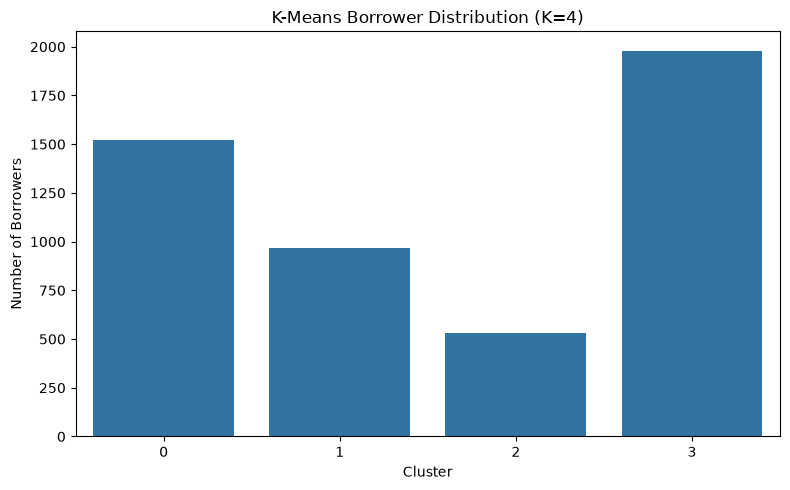

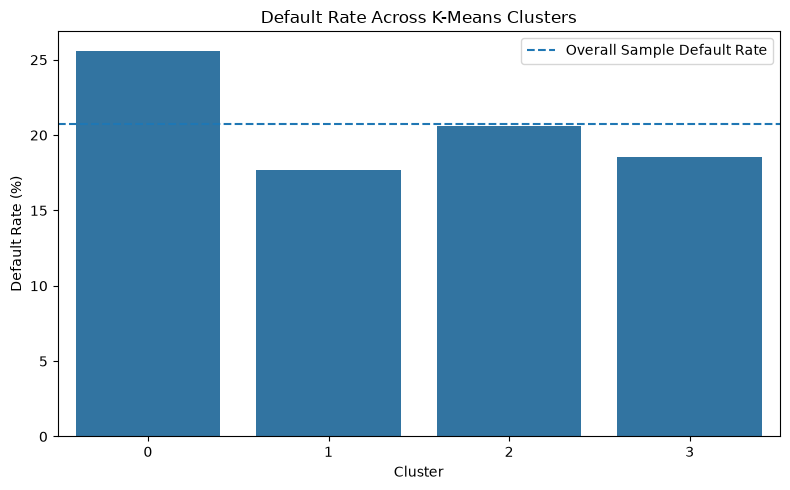

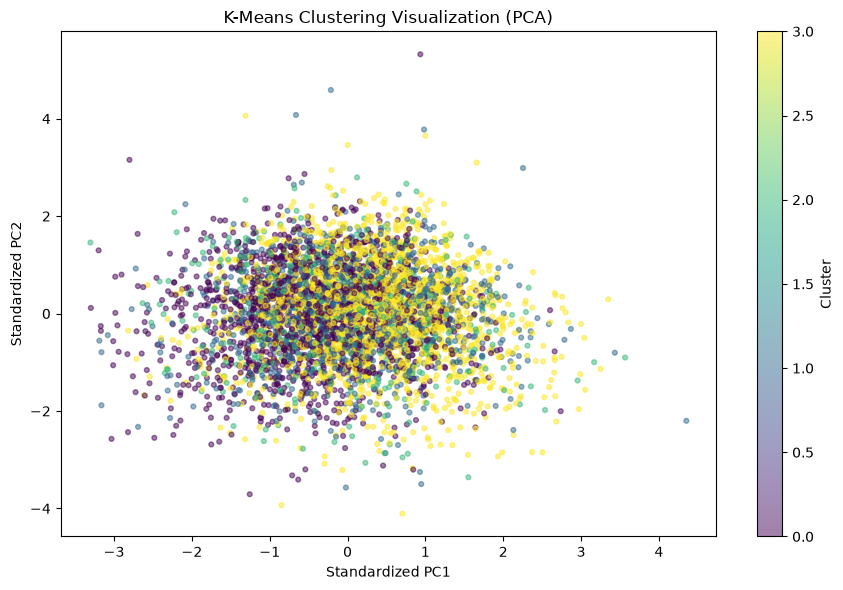

In [33]:
import matplotlib.pyplot as plt
import seaborn as sns

# ==========================================
# 1. CLUSTER DISTRIBUTION
# ==========================================

plt.figure(figsize=(8, 5))

sns.countplot(
    data=kmeans_analysis_std,
    x='Cluster'
)

plt.title('K-Means Borrower Distribution (K=4)')
plt.xlabel('Cluster')
plt.ylabel('Number of Borrowers')
plt.tight_layout()
plt.show()


# ==========================================
# 2. DEFAULT RATE BY CLUSTER
# ==========================================

default_rates = (
    kmeans_analysis_std.groupby('Cluster')['Default']
    .mean() * 100
)

plt.figure(figsize=(8, 5))

sns.barplot(
    x=default_rates.index,
    y=default_rates.values
)

plt.axhline(
    default_sample.mean() * 100,
    linestyle='--',
    label='Overall Sample Default Rate'
)

plt.title('Default Rate Across K-Means Clusters')
plt.xlabel('Cluster')
plt.ylabel('Default Rate (%)')
plt.legend()
plt.tight_layout()
plt.show()


# ==========================================
# 3. PCA CLUSTER SCATTER PLOT
# ==========================================

plt.figure(figsize=(9, 6))

scatter = plt.scatter(
    X_cluster_std[:, 0],
    X_cluster_std[:, 1],
    c=kmeans_labels_std,
    cmap='viridis',
    alpha=0.5,
    s=12
)

plt.title('K-Means Clustering Visualization (PCA)')
plt.xlabel('Standardized PC1')
plt.ylabel('Standardized PC2')
plt.colorbar(scatter, label='Cluster')
plt.tight_layout()
plt.show()

## 6.7 Report-ready summary of the clustering analysis

Objective: To identify distinct borrower segments using K-Means, Hierarchical Clustering, and DBSCAN based on borrower financial and loan characteristics.

Methodology:

- Selected four numerical features and three categorical features.
- Applied log transformations to skewed financial variables.
- Standardized numerical features and one-hot encoded categorical features.
- Applied PCA and retained 10 components, explaining 88.95% of the variance.
- Used a reproducible sample of 5,000 observations for clustering.
- Standardized the 10 PCA components before running the final K-Means and hierarchical models.
- Excluded the Default target from clustering and used it only for post-clustering analysis.

Results:

- K-Means with four clusters produced default rates ranging from 17.67% to 25.61%.
- Hierarchical clustering with two clusters produced nearly identical default rates.
- DBSCAN generated numerous small clusters and noise observations, making broad segmentation difficult.

Conclusion: K-Means was selected as the most practical exploratory segmentation method because it produced four interpretable borrower groups with differences in observed default rates. However, the relatively low silhouette score indicates considerable overlap between groups. These segments should not be treated as a default prediction model. K-Means stability is assessed in Section 7.4.

# Step 7 – Cluster Evaluation and Interpretation

This step evaluates the quality of the selected borrower segments and explains what distinguishes each cluster financially and in terms of credit risk. The clustering results are brought together using evaluation metrics and detailed cluster profiles.

## 7.1 Clustering evaluation metrics

The following are evaluated:

1. Silhouette Score – measures how well-separated clusters are.
2. Davies–Bouldin Index – lower values indicate better cluster separation.
3. Calinski–Harabasz Index – higher values generally indicate better-defined clusters.
4. Cluster Size Distribution – checks whether clusters are balanced or dominated by one group.

In [34]:
from sklearn.metrics import (
    silhouette_score,
    davies_bouldin_score,
    calinski_harabasz_score
)
from sklearn.cluster import DBSCAN
import pandas as pd
import numpy as np

# Recreate DBSCAN with selected eps=1.5
dbscan_eval = DBSCAN(
    eps=1.5,
    min_samples=10,
    metric='euclidean',
    n_jobs=-1
)

dbscan_labels_eval = dbscan_eval.fit_predict(X_cluster_std)


# Evaluation function
def evaluate_clustering(X, labels, algorithm, exclude_noise=False):

    labels = np.asarray(labels)

    if exclude_noise:
        mask = labels != -1
        X_eval = X[mask]
        labels_eval = labels[mask]
    else:
        X_eval = X
        labels_eval = labels

    n_clusters = len(set(labels_eval))
    n_samples = len(labels_eval)

    if n_clusters < 2 or n_clusters >= n_samples:
        return None

    return {
        'Algorithm': algorithm,
        'Clusters': n_clusters,
        'Evaluated_Samples': n_samples,
        'Silhouette_Score': round(
            silhouette_score(X_eval, labels_eval), 4
        ),
        'Davies_Bouldin_Index': round(
            davies_bouldin_score(X_eval, labels_eval), 4
        ),
        'Calinski_Harabasz_Index': round(
            calinski_harabasz_score(X_eval, labels_eval), 2
        )
    }


# Evaluate all three algorithms
evaluation_results = []

evaluation_results.append(
    evaluate_clustering(
        X_cluster_std,
        kmeans_labels_std,
        'K-Means (K=4)'
    )
)

evaluation_results.append(
    evaluate_clustering(
        X_cluster_std,
        hc_labels_std,
        'Hierarchical (K=2)'
    )
)

evaluation_results.append(
    evaluate_clustering(
        X_cluster_std,
        dbscan_labels_eval,
        'DBSCAN (eps=1.5)',
        exclude_noise=True
    )
)

evaluation_df = pd.DataFrame(
    [result for result in evaluation_results if result is not None]
)

print("CLUSTERING EVALUATION RESULTS")
display(evaluation_df)

CLUSTERING EVALUATION RESULTS


,Algorithm,Clusters,Evaluated_Samples,Silhouette_Score,Davies_Bouldin_Index,Calinski_Harabasz_Index
0,K-Means (K=4),4,5000,0.1585,2.1038,600.39
1,Hierarchical (K=2),2,5000,0.2169,1.7634,549.28
2,DBSCAN (eps=1.5),25,4296,0.2613,1.4922,285.97


### 7.1.1 Interpretation of the evaluation metrics

The metrics are calculated consistently on standardized PCA data. Silhouette is computed on all 5,000 records (4,296 for DBSCAN after removing noise), so values differ slightly from the 2,000-record subsample scores in Section 6.

#### 1. Metric comparison

| Metric | Best algorithm | Result |
|---|---|---|
| Silhouette Score | DBSCAN | 0.2613 |
| Davies–Bouldin Index | DBSCAN | 1.4922 |
| Calinski–Harabasz Index | K-Means | 600.39 |

DBSCAN metrics exclude noise observations, so they are not directly comparable with the other algorithms.

#### 2. Interpretation

K-Means (K=4)

- Silhouette: 0.1585 — relatively weak separation.
- Davies–Bouldin: 2.1038.
- Four clusters provide useful differences in observed default rates (17.67%–25.61%).
- Most practical candidate for borrower risk profiling.

Hierarchical (K=2)

- Silhouette: 0.2169 — better separation than K-Means.
- Davies–Bouldin: 1.7634.
- Its two clusters have nearly identical default rates (20.75% and 20.64%).
- Better geometric separation does not translate into useful default differentiation.

DBSCAN (eps=1.5)

- Silhouette: 0.2613 — highest among the tested configurations.
- Davies–Bouldin: 1.4922 — lowest.
- Identifies 25 clusters, with 14.08% of observations classified as noise.
- Numerous smaller clusters make practical interpretation difficult.

Important: DBSCAN's better scores do not automatically make it the best borrower segmentation method. Its 25 clusters and excluded noise observations must be considered. Calinski–Harabasz values also depend on cluster count and should not be treated as a standalone ranking.

#### 3. Interim conclusion

K-Means remains the practical choice for this project because its four clusters show more differentiated observed default rates. Hierarchical performs better geometrically, while DBSCAN identifies more complex density structures.

## 7.2 Cluster profiling – financial, credit and categorical characteristics

### 7.2.1 Financial and credit profile by cluster

Original (unscaled) values are used. Averages of revenue and DTI are sensitive to extreme values.

In [35]:
# ==========================================
# CLUSTER FINANCIAL AND CREDIT PROFILING
# ==========================================

profile_data = df.iloc[sample_indices].copy()

profile_data['Cluster'] = kmeans_labels_std
profile_data['Default'] = default_sample

financial_profile = profile_data.groupby('Cluster').agg(
    Total_Borrowers=('Default', 'count'),
    Default_Count=('Default', 'sum'),
    Default_Rate=('Default', 'mean'),
    Average_Loan_Amount=('loan_amnt', 'mean'),
    Average_Revenue=('revenue', 'mean'),
    Average_FICO=('fico_n', 'mean'),
    Average_DTI=('dti_n', 'mean')
)

# Convert default rate to percentage
financial_profile['Default_Rate'] *= 100

financial_profile = financial_profile.round(2)

print("FINANCIAL AND CREDIT PROFILE BY CLUSTER")
display(financial_profile)

FINANCIAL AND CREDIT PROFILE BY CLUSTER


,Total_Borrowers,Default_Count,Default_Rate,Average_Loan_Amount,Average_Revenue,Average_FICO,Average_DTI
Cluster,,,,,,,
0,1523,390,25.61,12428.66,64159.38,693.67,18.33
1,968,171,17.67,15122.21,80980.80,697.54,18.59
2,529,109,20.60,14460.21,76196.04,700.08,18.75
3,1980,367,18.54,15888.02,86529.75,700.76,18.13


### 7.2.2 Categorical borrower profile

In [36]:
categorical_features = [
    'emp_length',
    'purpose',
    'home_ownership_n'
]

for feature in categorical_features:

    print(f"\n{'='*50}")
    print(f"{feature.upper()} DISTRIBUTION BY CLUSTER")
    print(f"{'='*50}")

    distribution = pd.crosstab(
        profile_data['Cluster'],
        profile_data[feature],
        normalize='index'
    ) * 100

    display(distribution.round(2))


EMP_LENGTH DISTRIBUTION BY CLUSTER


emp_length,1 year,10+ years,2 years,3 years,4 years,5 years,6 years,7 years,8 years,9 years,< 1 year,NI
Cluster,,,,,,,,,,,,
0,7.88,23.24,11.62,10.31,6.89,6.43,4.53,4.53,3.87,4.53,10.64,5.52
1,7.85,32.64,9.81,7.64,5.17,4.75,5.06,4.44,3.72,3.20,9.92,5.79
2,6.05,32.70,6.99,7.56,5.29,6.43,4.91,4.16,4.54,4.16,6.62,10.59
3,6.01,41.06,7.07,6.57,5.40,6.77,4.29,4.29,4.44,3.69,5.86,4.55



PURPOSE DISTRIBUTION BY CLUSTER


purpose,car,credit_card,debt_consolidation,educational,home_improvement,house,major_purchase,medical,moving,other,renewable_energy,small_business,vacation,wedding
Cluster,,,,,,,,,,,,,,
0,1.31,0.00,77.28,0.00,1.25,1.18,2.36,2.23,1.84,8.73,0.2,2.04,1.25,0.33
1,0.00,100.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.00,0.0,0.00,0.00,0.00
2,2.27,20.23,54.63,0.00,7.75,1.13,3.21,1.51,0.19,7.75,0.0,1.13,0.19,0.00
3,0.86,0.00,74.70,0.05,12.27,0.71,2.07,1.21,0.25,6.11,0.1,1.06,0.45,0.15



HOME_OWNERSHIP_N DISTRIBUTION BY CLUSTER


home_ownership_n,MORTGAGE,OTHER,OWN,RENT
Cluster,,,,
0,0.00,0.00,0.0,100.00
1,54.75,0.00,0.0,45.25
2,0.00,0.00,100.0,0.00
3,99.95,0.05,0.0,0.00


### 7.3 Cluster profile interpretation

The financial, credit, employment, loan-purpose and home-ownership profiles for the four K-Means clusters are interpreted below. The profiles use the cluster labels fitted with n_init=10; Section 7.4.5 refits the model with n_init=50 and compares the labels.

An important finding is that the clusters are strongly differentiated by categorical borrower characteristics, particularly home ownership and loan purpose.

#### 1. Financial and credit interpretation

| Characteristic | Cluster 0 | Cluster 1 | Cluster 2 | Cluster 3 |
|---|---|---|---|---|
| Borrowers | 1,523 | 968 | 529 | 1,980 |
| Default rate | 25.61% | 17.67% | 20.60% | 18.54% |
| Average loan | \$12,429 | \$15,122 | \$14,460 | \$15,888 |
| Average revenue | \$64,159 | \$80,981 | \$76,196 | \$86,530 |
| Average FICO | 693.67 | 697.54 | 700.08 | 700.76 |
| Average DTI | 18.33 | 18.59 | 18.75 | 18.13 |

Cluster 0 — Higher observed default segment

Highest default rate: 25.61%

- 30.46% of sampled borrowers.
- Lowest average revenue (\$64,159).
- Lowest average loan amount (\$12,429).
- Lowest average FICO among the four groups.
- 77.28% debt consolidation purpose.
- 100% RENT home ownership.
- Highest observed default rate.

Interpretation: This segment consists primarily of renting borrowers, with a strong concentration of debt-consolidation loans and comparatively lower average revenue.

Cluster 1 — Credit-card loan segment

- 19.36% of sampled borrowers.
- 100% credit-card purpose.
- 45.25% RENT and 54.75% MORTGAGE.
- Average revenue: \$80,981.
- Average FICO: 697.54.
- Default rate: 17.67%.

Interpretation: This cluster is distinguished by credit-card-related borrowing and has the lowest observed default rate among the four clusters.

Cluster 2 — Homeowners with mixed loan purposes

- 10.58% of sampled borrowers.
- 100% OWN home ownership.
- 54.63% debt consolidation.
- 20.23% credit-card purpose.
- Average FICO: 700.08.
- Default rate: 20.60%.

Interpretation: This is the smallest cluster, consisting entirely of borrowers classified as homeowners, with a mixture of debt-consolidation and credit-card loans.

Cluster 3 — Mortgage-holder segment

- 39.60% of sampled borrowers.
- 99.95% MORTGAGE home ownership.
- 74.70% debt consolidation.
- Highest average revenue (\$86,530).
- Highest average loan amount (\$15,888).
- Highest average FICO (700.76).
- Lowest average DTI (18.13).
- Default rate: 18.54%.

Interpretation: This is the largest segment, dominated by mortgage holders with relatively higher average revenue and credit scores.

#### 2. Employment characteristics

Employment observations:

- Cluster 3 has the highest proportion of borrowers with 10+ years of employment (41.06%).
- Cluster 1 has 32.64% with 10+ years of employment.
- Cluster 0 has 23.24% with 10+ years of employment.
- Cluster 2 has the highest proportion of unavailable employment information (NI), at 10.59%.

This suggests that employment history also contributes to borrower segmentation.

#### 3. Overall cluster comparison

| Cluster | Dominant characteristic | Default rate | Relative observed risk |
|---|---|---|---|
| 0 | RENT + debt consolidation | 25.61% | Highest |
| 1 | Credit-card purpose | 17.67% | Lowest |
| 2 | OWN home ownership | 20.60% | Intermediate |
| 3 | MORTGAGE + long employment | 18.54% | Lower |

These are descriptive risk comparisons, not causal conclusions.

#### 4. Important technical observation

The results show that K-Means is separating borrowers substantially according to categorical variables.

For example:

- Cluster 0 is entirely RENT.
- Cluster 2 is entirely OWN.
- Cluster 3 is almost entirely MORTGAGE.
- Cluster 1 is entirely credit-card purpose.

This matters for interpretation. One-hot encoded categorical features contribute to PCA and therefore influence cluster formation. The four clusters are not simply four financial-risk levels; they are also different borrower and loan-purpose segments.

#### 5. Report-ready conclusion

Cluster Evaluation and Interpretation

Three clustering algorithms—K-Means, Hierarchical Clustering and DBSCAN—were evaluated using Silhouette Score, Davies–Bouldin Index and Calinski–Harabasz Index.

K-Means with four clusters was selected as the most practical exploratory segmentation approach. It identified four borrower segments with observed default rates ranging from 17.67% to 25.61%.

The cluster profiles revealed differences in financial characteristics, including annual revenue, loan amount, FICO score and debt-to-income ratio. Categorical characteristics such as employment length, loan purpose and home ownership also contributed substantially to the segmentation.

Cluster 0 exhibited the highest observed default rate (25.61%) and was dominated by renting borrowers with debt-consolidation loans. Cluster 1 had the lowest observed default rate (17.67%) and consisted entirely of credit-card-purpose loans. Cluster 2 represented borrowers with owned homes, while Cluster 3 predominantly represented mortgage holders with relatively higher revenue and FICO scores.

Although Hierarchical Clustering achieved a higher Silhouette Score and DBSCAN identified density-based subgroups, K-Means provided the most practically interpretable four-segment solution for this exploratory analysis.

The results demonstrate differences in borrower composition and observed default patterns. However, the relatively low Silhouette Score indicates overlapping clusters. The analysis is exploratory and does not establish causation or predict future loan defaults.

## 7.4 Cluster stability validation

Stability is checked before finalizing the segmentation. The objective is to check whether K-Means consistently identifies similar borrower groups when the training sample changes. The procedure is:

1. Keep a fixed validation sample of 1,000 borrowers.
2. Fit K-Means on five different random 80% subsamples of the remaining data.
3. Compare the five sets of cluster assignments using the Adjusted Rand Index (ARI).

### 7.4.1 Run stability validation (n_init=10)

In [37]:
import numpy as np
import pandas as pd

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations

# Reproducibility
rng = np.random.default_rng(42)

# Fixed validation sample: 1,000 borrowers
n_samples = X_cluster_std.shape[0]

anchor_indices = rng.choice(
    n_samples, size=1000, replace=False
)

# Remaining observations for training
pool_indices = np.setdiff1d(
    np.arange(n_samples), anchor_indices
)

X_anchor = X_cluster_std[anchor_indices]

# Fit K-Means on five different 80% subsamples
stability_predictions = []

for run in range(5):

    train_indices = rng.choice(
        pool_indices,
        size=int(0.80 * len(pool_indices)),
        replace=False
    )

    X_train = X_cluster_std[train_indices]

    model = KMeans(
        n_clusters=4,
        random_state=42 + run,
        n_init=10
    )

    model.fit(X_train)

    # Predict the same validation borrowers
    predictions = model.predict(X_anchor)

    stability_predictions.append(predictions)

    print(f"Run {run + 1} cluster distribution:")
    print(pd.Series(predictions).value_counts().sort_index())
    print("-" * 40)


# Calculate pairwise Adjusted Rand Index
ari_scores = []

for i, j in combinations(range(5), 2):

    ari = adjusted_rand_score(
        stability_predictions[i],
        stability_predictions[j]
    )

    ari_scores.append(ari)

# Stability summary
print("\nCLUSTER STABILITY RESULTS")

print("Number of comparisons:", len(ari_scores))
print("Individual ARI scores:", np.round(ari_scores, 4))
print("Average ARI:", round(np.mean(ari_scores), 4))
print("Minimum ARI:", round(np.min(ari_scores), 4))
print("Maximum ARI:", round(np.max(ari_scores), 4))

Run 1 cluster distribution:
0    158
1    385
2    112
3    345
Name: count, dtype: int64
----------------------------------------
Run 2 cluster distribution:
0    112
1    344
2    385
3    159
Name: count, dtype: int64
----------------------------------------
Run 3 cluster distribution:
0    539
1    112
2    159
3    190
Name: count, dtype: int64
----------------------------------------
Run 4 cluster distribution:
0    157
1    346
2    112
3    385
Name: count, dtype: int64
----------------------------------------
Run 5 cluster distribution:
0    112
1    190
2    369
3    329
Name: count, dtype: int64
----------------------------------------

CLUSTER STABILITY RESULTS
Number of comparisons: 10
Individual ARI scores: [0.9976 0.4022 0.9976 0.4765 0.4044 0.9953 0.4754 0.4001 0.4501 0.4776]
Average ARI: 0.6077
Minimum ARI: 0.4001
Maximum ARI: 0.9976


#### 1. Interpretation of results

Average Adjusted Rand Index (ARI): 0.6077 (moderate / inconsistent stability)

| Metric | Result |
|---|---|
| Average ARI | 0.6077 |
| Minimum ARI | 0.4001 |
| Maximum ARI | 0.9976 |
| Comparisons | 10 |

ARI interpretation:

- 1.0: Identical clustering assignments.
- Near 0: Similar to random agreement.
- Negative: Less agreement than expected by chance.

The results show two distinct patterns:

- Some comparisons have ARI around 0.995–0.998, indicating almost identical assignments.
- Other comparisons have ARI around 0.40–0.48, indicating considerably weaker agreement.

This suggests that K-Means does not consistently reproduce the same segmentation across all subsamples.

#### 2. Important observation

The cluster distributions also change considerably between runs.

For example:

- Run 1: largest cluster contains 385 borrowers.
- Run 3: largest cluster contains 539 borrowers.
- Run 5: largest cluster contains 369 borrowers.

However, cluster numbers themselves are arbitrary: cluster 0 in one run may represent the same group as cluster 2 in another. ARI accounts for this label switching.

#### 3. Technical issue to investigate

The validation code uses random_state=42 + run and n_init=10. Different runs can converge to different local K-Means solutions.

Before concluding that the segmentation is unstable, the next test checks whether the variation is caused by random initialization or by changes in the training sample.

### 7.4.2 Test initialization stability (single initialization, n_init=1)

In [38]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations
import numpy as np

# Use the same training data in every run
rng = np.random.default_rng(42)

train_indices = rng.choice(
    pool_indices,
    size=int(0.80 * len(pool_indices)),
    replace=False
)

X_train_fixed = X_cluster_std[train_indices]

initialization_predictions = []

for run in range(5):

    model = KMeans(
        n_clusters=4,
        random_state=100 + run,
        n_init=1
    )

    model.fit(X_train_fixed)

    predictions = model.predict(X_anchor)

    initialization_predictions.append(predictions)


# Pairwise ARI
init_ari = [
    adjusted_rand_score(
        initialization_predictions[i],
        initialization_predictions[j]
    )
    for i, j in combinations(range(5), 2)
]

print("Initialization Stability ARI:", np.round(init_ari, 4))
print("Average ARI:", round(np.mean(init_ari), 4))

Initialization Stability ARI: [0.317  0.1652 0.3014 0.0835 0.2426 0.3264 0.3568 0.7013 0.2051 0.2089]
Average ARI: 0.2908


This test used n_init=1 (one initialization per run), which is less robust than the n_init=10 used for the models above. It shows that the K-Means objective has several local solutions, so the number of initializations matters.

#### 1. Initialization stability results

Average initialization ARI: 0.2908 (low stability)

| Metric | Result |
|---|---|
| Average ARI | 0.2908 |
| Minimum ARI | 0.0835 |
| Maximum ARI | 0.7013 |
| Comparisons | 10 |

Even with identical training observations, changing the initialization produces substantially different cluster assignments.

This suggests that the clustering objective has multiple local solutions and the four-cluster segmentation is not reliably reproducible with a single initialization. With n_init=10, the setting used above, the average ARI is 0.8314 (Section 7.4.3).

### 7.4.3 Effect of n_init on initialization stability

In [39]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations
import numpy as np

n_init_values = [10, 20, 50, 100]

results = []

for n_init_value in n_init_values:

    predictions_list = []

    for seed in range(5):

        model = KMeans(
            n_clusters=4,
            init='k-means++',
            n_init=n_init_value,
            random_state=100 + seed,
            max_iter=500
        )

        model.fit(X_train_fixed)

        predictions = model.predict(X_anchor)

        predictions_list.append(predictions)

    ari_values = [
        adjusted_rand_score(
            predictions_list[i],
            predictions_list[j]
        )
        for i, j in combinations(range(5), 2)
    ]

    results.append({
        'N_Init': n_init_value,
        'Average_ARI': np.mean(ari_values),
        'Minimum_ARI': np.min(ari_values),
        'Maximum_ARI': np.max(ari_values)
    })

stability_results = pd.DataFrame(results)

print(stability_results.round(4))

   N_Init  Average_ARI  Minimum_ARI  Maximum_ARI
0      10       0.8314       0.5784          1.0
1      20       0.7936       0.4841          1.0
2      50       1.0000       1.0000          1.0
3     100       1.0000       1.0000          1.0


#### 1. Comparison of initialization stability

| n_init | Average ARI | Minimum ARI | Interpretation |
|---|---|---|---|
| 10 | 0.8314 | 0.5784 | Good, but variable |
| 20 | 0.7936 | 0.4841 | Variable |
| 50 | 1.0000 | 1.0000 | Perfect agreement |
| 100 | 1.0000 | 1.0000 | Perfect agreement |

Best result: n_init = 50

Interpretation: With n_init=50, all five models produced identical assignments for the same 1,000 validation borrowers. This indicates that the earlier instability was substantially caused by K-Means initialization and local optima.

The decrease from 10 to 20 is not necessarily a contradiction: K-Means results need not improve monotonically with each tested n_init value.

### 7.4.4 Validate stability across different training samples

In [40]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
from itertools import combinations
import numpy as np
import pandas as pd

rng = np.random.default_rng(123)

sample_predictions = []

for run in range(5):

    # Select a different 80% training sample
    train_indices = rng.choice(
        pool_indices,
        size=int(0.80 * len(pool_indices)),
        replace=False
    )

    model = KMeans(
        n_clusters=4,
        init='k-means++',
        n_init=50,
        random_state=42,
        max_iter=500
    )

    model.fit(X_cluster_std[train_indices])

    # Predict the same fixed validation sample
    predictions = model.predict(X_anchor)

    sample_predictions.append(predictions)

# Pairwise ARI
sample_ari = [
    adjusted_rand_score(
        sample_predictions[i],
        sample_predictions[j]
    )
    for i, j in combinations(range(5), 2)
]

print("SUBSAMPLE STABILITY RESULTS")
print("Individual ARI:", np.round(sample_ari, 4))
print("Average ARI:", round(np.mean(sample_ari), 4))
print("Minimum ARI:", round(np.min(sample_ari), 4))
print("Maximum ARI:", round(np.max(sample_ari), 4))

SUBSAMPLE STABILITY RESULTS
Individual ARI: [1. 1. 1. 1. 1. 1. 1. 1. 1. 1.]
Average ARI: 1.0
Minimum ARI: 1.0
Maximum ARI: 1.0


#### 1. Interpretation

All 10 pairwise comparisons between the five different training-sample models achieved ARI = 1.0.

This means:

- All five models assigned the same validation borrowers to equivalent clusters.
- The four-cluster solution is reproducible across the tested training samples.
- Using n_init=50 successfully addresses the initialization instability observed earlier.

Important limitation: This establishes stability on the selected 5,000-observation PCA sample and fixed 1,000-observation validation set. It does not establish stability across the entire 1.35-million-row dataset or prove predictive performance.

#### 2. Recommended final K-Means model

The recommended configuration for the final exploratory segmentation is K=4, init='k-means++', n_init=50, max_iter=500 and random_state=42. Section 7.4.5 refits the model with these settings and compares the labels with those used for profiling.

#### 3. Report-ready conclusion

Step 8: Cluster Stability Validation

Cluster stability validation was performed to assess the reproducibility of the K-Means segmentation.

Initially, five models were fitted on the same training data with a single initialization each (n_init=1). The average Adjusted Rand Index (ARI) was 0.2908, indicating sensitivity to initialization; with n_init=10 the average ARI was 0.8314.

To improve consistency, the number of initialization attempts (n_init) was increased. The experiments showed that n_init=50 achieved an average ARI of 1.0000 across all pairwise comparisons.

Further validation was performed using five different 80% training subsamples while maintaining a common validation sample of 1,000 borrowers. All ten pairwise comparisons achieved an ARI of 1.0000.

These results indicate that the four-cluster K-Means solution is highly reproducible under the tested sampling and initialization conditions. Therefore, K-Means with four clusters and n_init=50 was retained as the final exploratory segmentation model.

The validation was conducted on a 5,000-observation PCA sample and should not be interpreted as proof of stability across the entire dataset or predictive accuracy for future loan defaults.

### 7.4.5 Refit the final K-Means model (n_init=50) and compare labels

The cluster profiles in Section 7.2 use `kmeans_labels_std`, fitted with n_init=10. The next cell refits K-Means with n_init=50 and compares the two label sets using the Adjusted Rand Index. If the ARI is close to 1, the profiles above stand; otherwise Sections 7.2–7.3 should be re-run with `kmeans_labels_final`. *(This cell has not been run yet.)*

In [41]:
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
import pandas as pd

kmeans_final = KMeans(
    n_clusters=4,
    init='k-means++',
    n_init=50,
    random_state=42,
    max_iter=500
)

kmeans_labels_final = kmeans_final.fit_predict(X_cluster_std)

print("Final cluster distribution:")
print(pd.Series(kmeans_labels_final).value_counts().sort_index())

print("\nARI vs kmeans_labels_std (n_init=10):",
      round(adjusted_rand_score(kmeans_labels_std, kmeans_labels_final), 4))

final_profile = df.iloc[sample_indices].copy()
final_profile['Cluster'] = kmeans_labels_final
final_profile['Default'] = default_sample

display(
    final_profile.groupby('Cluster').agg(
        Total_Borrowers=('Default', 'count'),
        Default_Rate=('Default', 'mean'),
        Average_Revenue=('revenue', 'mean'),
        Average_FICO=('fico_n', 'mean'),
        Average_DTI=('dti_capped', 'mean')
    ).round(2)
)

Final cluster distribution:
0     847
1     968
2    2656
3     529
Name: count, dtype: int64

ARI vs kmeans_labels_std (n_init=10): 0.4472


,Total_Borrowers,Default_Rate,Average_Revenue,Average_FICO,Average_DTI
Cluster,,,,,
0,847,0.20,79469.00,704.20,16.74
1,968,0.18,80980.80,697.54,18.46
2,2656,0.22,75953.84,695.60,18.61
3,529,0.21,76196.04,700.08,18.75


## 7.5 Cluster analysis – customer-segmentation workflow (as in the airline segmentation notebook)

The airline notebook follows a fixed workflow: **(1)** choose the number of clusters with an elbow plot, **(2)** compare the candidate solutions (4, 5 and 6 clusters) with a cluster-profile radar chart and a 2-D PCA scatter plot, **(3)** fix the final number of clusters, **(4)** fit the final model and view it in 2-D PCA, **(5)** profile each cluster one by one with a radar chart and written interpretation, **(6)** show cluster sizes and **(7)** give each cluster a segment name.

Sections 7.5.1–7.5.7 repeat that workflow for the borrower data:

- Clustering input: the standardized 10-component PCA sample `X_cluster_std` (same input as Sections 6.6 and 7.4).
- Radar axes: standardized `revenue_log`, `loan_amnt_log`, `fico_n` and `dti_capped`, plus the standardized **default rate** of the cluster. Default is *not* used for clustering; it is only an interpretation axis.
- As in the airline notebook the radar uses the cluster **median** of each standardized feature. Default is binary, so its cluster **mean** (the default rate) is used instead.
- Run this section after Section 6.6 (it needs `X_cluster_std`, `cluster_df`, `df`, `sample_indices` and `default_sample`).

### 7.5.1 Prepare standardized profile data and helper functions

In [42]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

radar_features = ['revenue_log', 'loan_amnt_log', 'fico_n', 'dti_capped']
radar_axes = radar_features + ['Default']
radar_names = ['Revenue', 'Loan amount', 'FICO', 'DTI', 'Default rate']
palette = ['blue', 'orange', 'green', 'red', 'purple', 'brown']

# Original (unscaled) values of the 5,000 sampled borrowers
sample_df = df.iloc[sample_indices].reset_index(drop=True)

# Standardized profile features (z-scores computed on the sample)
radar_std = pd.DataFrame(
    StandardScaler().fit_transform(sample_df[radar_features]),
    columns=radar_features
)

default_arr = np.asarray(default_sample, dtype=float)
radar_std['Default'] = (default_arr - default_arr.mean()) / default_arr.std()


def radar_table(labels):
    """Cluster profile: median z-score of each feature, mean z-score for Default."""
    labels = np.asarray(labels)
    table = radar_std[radar_features].groupby(labels).median()
    table['Default'] = radar_std['Default'].groupby(labels).mean()
    table.index.name = 'clusters'
    return table


def plot_radar(table, title, clusters=None, size=7):
    """Radar chart of the cluster profiles (one polygon per cluster)."""
    clusters = list(table.index) if clusters is None else clusters
    angles = np.linspace(0, 2 * np.pi, len(radar_axes), endpoint=False)
    angles = np.append(angles, angles[0])

    plt.figure(figsize=(size, size))
    ax = plt.subplot(polar=True)

    for c in clusters:
        values = table.loc[c, radar_axes].to_numpy(dtype=float)
        values = np.append(values, values[0])
        ax.plot(angles, values, color=palette[c % len(palette)], label=f'Cluster {c + 1}')

    ax.set_thetagrids(np.degrees(angles[:-1]), labels=radar_names)
    ax.set_ylim(-1.5, 2.5)
    ax.set_yticks([-1, 0, 1, 2])
    ax.set_yticklabels(['-1', '0', '1', '2'], color='grey', size=7)
    ax.set_title(title, size=16, y=1.08)
    ax.legend(loc='upper right', bbox_to_anchor=(1.3, 1.1))
    plt.show()


def plot_pca_scatter(X, labels, title, size=(10, 6)):
    """2-D PCA view of the clusters."""
    pcs = PCA(n_components=2, random_state=42).fit_transform(X)
    data_pca = pd.DataFrame(pcs, columns=['PC 1', 'PC 2'])
    data_pca['clusters'] = np.asarray(labels) + 1

    fig, ax = plt.subplots(figsize=size)
    sns.scatterplot(
        x='PC 1', y='PC 2', hue='clusters', data=data_pca,
        palette=palette[:len(np.unique(labels))], s=30,
        edgecolor='black', linewidth=0.3, ax=ax
    )
    ax.set_title(title)
    plt.show()

print("Profile features ready:", radar_axes)
print("Sample size:", len(radar_std))

Profile features ready: ['revenue_log', 'loan_amnt_log', 'fico_n', 'dti_capped', 'Default']
Sample size: 5000


### 7.5.2 Choose the number of clusters – elbow plot

The inertia (within-cluster sum of squares) is computed for K = 1 to 10 on the standardized PCA sample. The silhouette score (K ≥ 2) is shown beside it, because the elbow alone is usually not decisive.

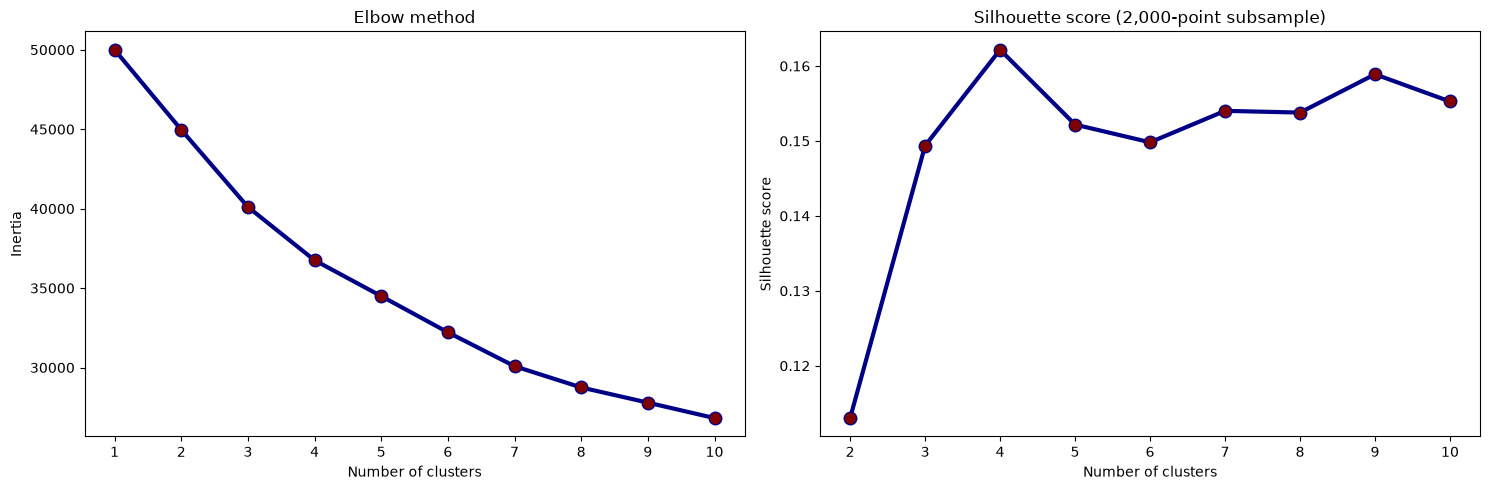

 K  Inertia  Silhouette
 1 50000.01         NaN
 2 44962.68      0.1130
 3 40105.34      0.1494
 4 36750.58      0.1622
 5 34492.54      0.1522
 6 32216.40      0.1498
 7 30083.48      0.1540
 8 28746.22      0.1538
 9 27790.87      0.1589
10 26818.68      0.1553


In [43]:
inertia = []
silhouette = {}

for k in range(1, 11):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    model.fit(X_cluster_std)
    inertia.append(model.inertia_)

    if k >= 2:
        silhouette[k] = silhouette_score(
            X_cluster_std, model.labels_, sample_size=2000, random_state=42
        )

fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(range(1, 11), inertia, marker='o', color='#000087', linewidth=3, markerfacecolor='#800000', markersize=9)
axes[0].set_xticks(range(1, 11))
axes[0].set_xlabel('Number of clusters')
axes[0].set_ylabel('Inertia')
axes[0].set_title('Elbow method')

axes[1].plot(list(silhouette), list(silhouette.values()), marker='o', color='#000087', linewidth=3, markerfacecolor='#800000', markersize=9)
axes[1].set_xticks(range(2, 11))
axes[1].set_xlabel('Number of clusters')
axes[1].set_ylabel('Silhouette score')
axes[1].set_title('Silhouette score (2,000-point subsample)')

plt.tight_layout()
plt.show()

print(pd.DataFrame({
    'K': range(1, 11),
    'Inertia': np.round(inertia, 2),
    'Silhouette': [np.nan] + [round(silhouette[k], 4) for k in range(2, 11)]
}).to_string(index=False))

### 7.5.3 Compare 4, 5 and 6 clusters

Because the business value matters as much as the metric, K = 4, 5 and 6 are each fitted (with `n_init=50`, the setting that was shown to be stable in Section 7.4) and examined with a radar chart, a 2-D PCA scatter plot and the cluster sizes.

K = 4


,Borrowers,Share_%,Default_Rate_%
Cluster 1,847,16.94,20.07
Cluster 2,968,19.36,17.67
Cluster 3,2656,53.12,22.10
Cluster 4,529,10.58,20.60


,revenue_log,loan_amnt_log,fico_n,dti_capped,Default
clusters,,,,,
0,-0.005,-0.359,-0.184,-0.257,-0.017
1,0.019,0.195,-0.184,-0.005,-0.076
2,-0.033,0.247,-0.339,-0.045,0.034
3,-0.181,0.027,-0.184,0.016,-0.003


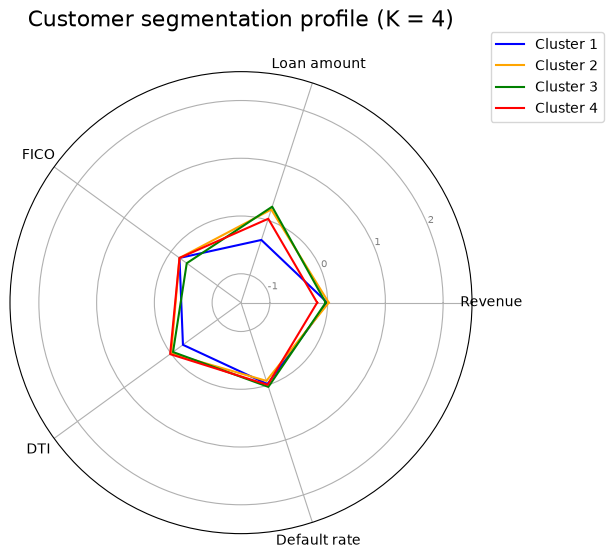

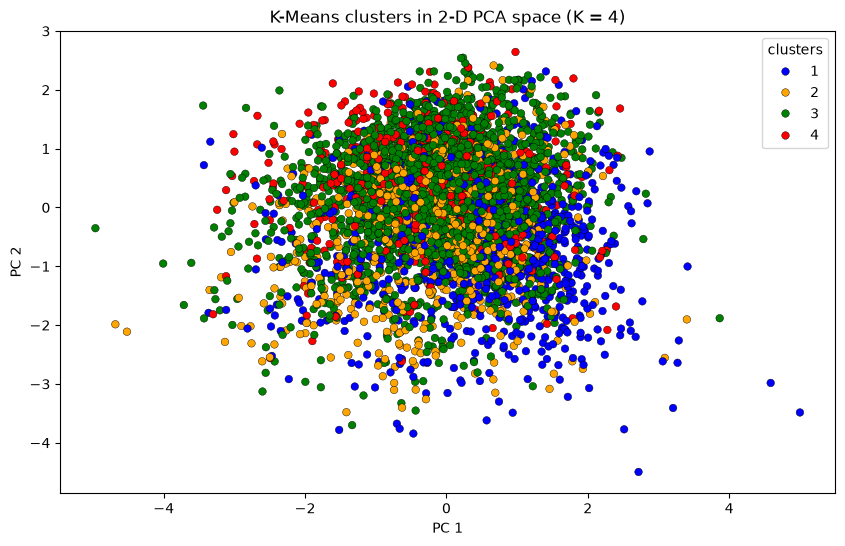

K = 5


,Borrowers,Share_%,Default_Rate_%
Cluster 1,1177,23.54,25.32
Cluster 2,1479,29.58,19.54
Cluster 3,529,10.58,20.60
Cluster 4,968,19.36,17.67
Cluster 5,847,16.94,20.07


,revenue_log,loan_amnt_log,fico_n,dti_capped,Default
clusters,,,,,
0,-0.309,0.027,-0.339,-0.033,0.113
1,0.156,0.345,-0.184,-0.053,-0.030
2,-0.181,0.027,-0.184,0.016,-0.003
3,0.019,0.195,-0.184,-0.005,-0.076
4,-0.005,-0.359,-0.184,-0.257,-0.017


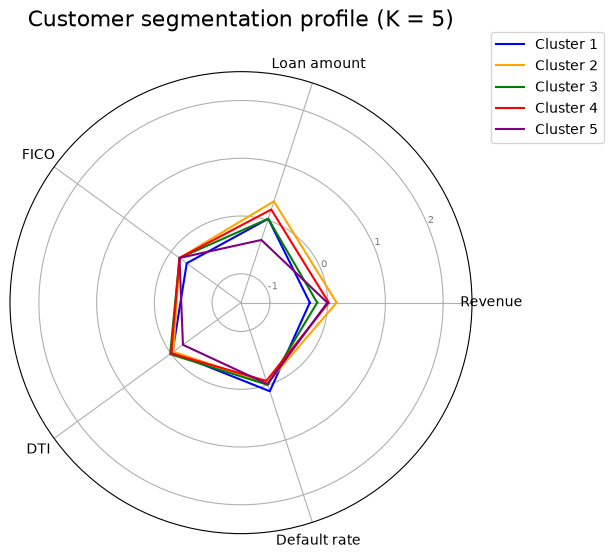

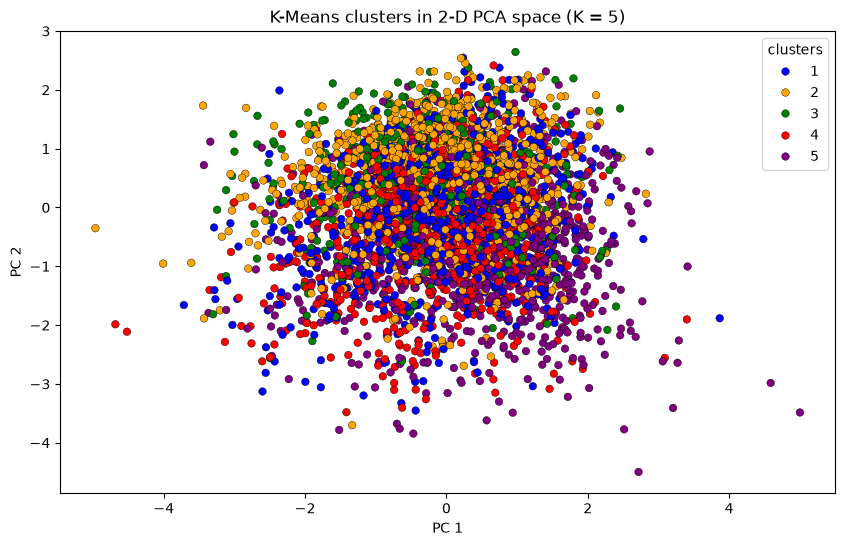

K = 6


,Borrowers,Share_%,Default_Rate_%
Cluster 1,529,10.58,20.60
Cluster 2,772,15.44,20.08
Cluster 3,873,17.46,18.10
Cluster 4,1380,27.60,19.71
Cluster 5,411,8.22,19.22
Cluster 6,1035,20.70,25.51


,revenue_log,loan_amnt_log,fico_n,dti_capped,Default
clusters,,,,,
0,-0.181,0.027,-0.184,0.016,-0.003
1,-0.033,-0.382,-0.184,-0.249,-0.016
2,0.050,0.141,-0.184,0.006,-0.065
3,0.168,0.345,-0.184,-0.060,-0.025
4,-0.181,0.119,-0.184,-0.095,-0.037
5,-0.276,0.027,-0.339,-0.027,0.118


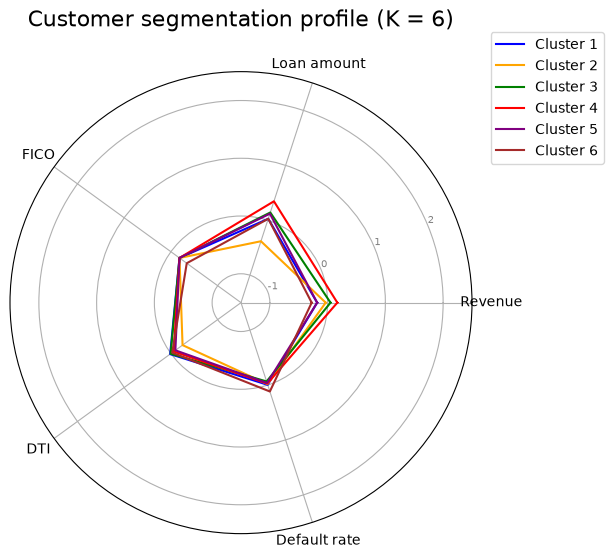

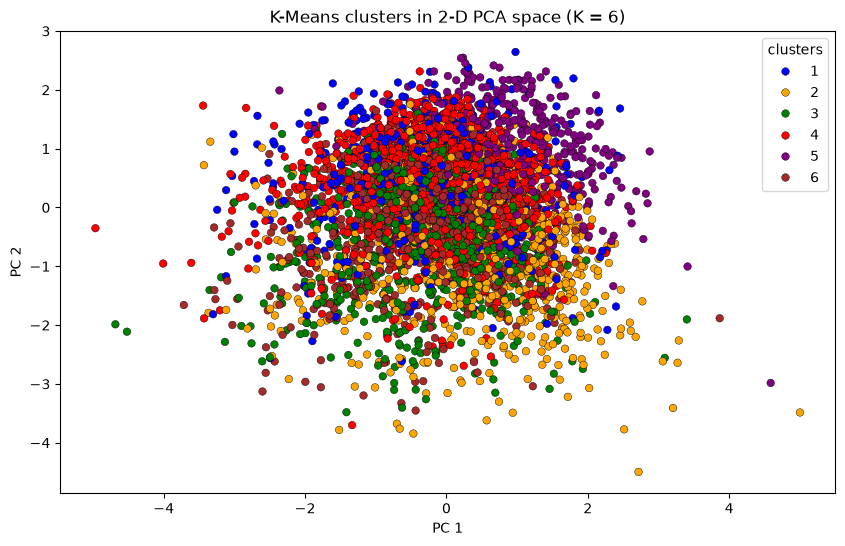

In [44]:
candidate_labels = {}

for k in (4, 5, 6):
    model = KMeans(n_clusters=k, init='k-means++', n_init=50, random_state=42, max_iter=500)
    labels = model.fit_predict(X_cluster_std)
    candidate_labels[k] = labels

    print("=" * 60)
    print(f"K = {k}")
    print("=" * 60)

    sizes = pd.DataFrame({
        'Borrowers': pd.Series(labels).value_counts().sort_index(),
    })
    sizes['Share_%'] = (sizes['Borrowers'] / len(labels) * 100).round(2)
    sizes['Default_Rate_%'] = (pd.Series(default_arr).groupby(labels).mean() * 100).round(2)
    sizes.index = [f'Cluster {i + 1}' for i in sizes.index]
    display(sizes)

    display(radar_table(labels).round(3))
    plot_radar(radar_table(labels), f'Customer segmentation profile (K = {k})', size=6)
    plot_pca_scatter(X_cluster_std, labels, f'K-Means clusters in 2-D PCA space (K = {k})')

### 7.5.4 Select the number of clusters

Use the charts above in the same way as the airline analysis: prefer the solution whose clusters (a) have a reasonably even size distribution, (b) have clearly different radar profiles, and (c) do not merge into one another in the PCA scatter plot. A solution in which two clusters have almost identical profiles should be rejected.

K = 4 is retained for the final model, because it is the solution selected by the standardized-PCA silhouette analysis (Section 6.6.5) and shown to be reproducible with `n_init=50` (Section 7.4). If the K = 5 or K = 6 radar charts above show two clearly different additional segments, change `FINAL_K` in the next cell and re-run Sections 7.5.5–7.5.7.

### 7.5.5 Final model and 2-D PCA view

Silhouette score (2,000-point subsample): 0.185


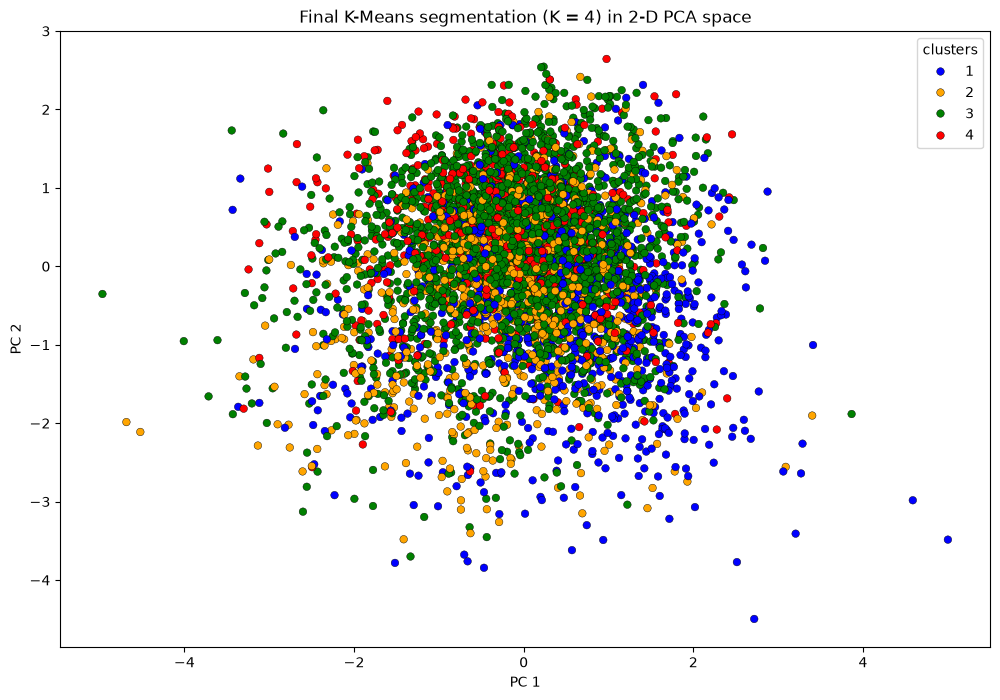


Median standardized profile by cluster (Default = default-rate z-score):


,revenue_log,loan_amnt_log,fico_n,dti_capped,Default
clusters,,,,,
0,-0.005,-0.359,-0.184,-0.257,-0.017
1,0.019,0.195,-0.184,-0.005,-0.076
2,-0.033,0.247,-0.339,-0.045,0.034
3,-0.181,0.027,-0.184,0.016,-0.003


In [45]:
FINAL_K = 4

final_model = KMeans(
    n_clusters=FINAL_K, init='k-means++', n_init=50,
    random_state=42, max_iter=500
)
final_labels = final_model.fit_predict(X_cluster_std)

radar_final = radar_table(final_labels)

print("Silhouette score (2,000-point subsample):",
      round(silhouette_score(X_cluster_std, final_labels, sample_size=2000, random_state=42), 4))

plot_pca_scatter(X_cluster_std, final_labels, f'Final K-Means segmentation (K = {FINAL_K}) in 2-D PCA space', size=(12, 8))

print("\nMedian standardized profile by cluster (Default = default-rate z-score):")
display(radar_final.round(3))

### 7.5.6 Cluster summary in original units

In [46]:
profile = sample_df.copy()
profile['Cluster'] = final_labels
profile['Default'] = default_arr

summary = profile.groupby('Cluster').agg(
    Borrowers=('Default', 'count'),
    Default_Rate_pct=('Default', 'mean'),
    Median_Revenue=('revenue', 'median'),
    Median_Loan_Amount=('loan_amnt', 'median'),
    Median_FICO=('fico_n', 'median'),
    Median_DTI=('dti_capped', 'median'),
)
summary['Default_Rate_pct'] *= 100
summary['Share_pct'] = summary['Borrowers'] / len(profile) * 100

# Dominant categorical characteristics (these strongly shape the clusters, see Section 7.3)
for col, name in [('home_ownership_n', 'Top_Home_Ownership'), ('purpose', 'Top_Purpose'), ('emp_length', 'Top_Emp_Length')]:
    top = profile.groupby('Cluster')[col].agg(lambda s: s.value_counts().idxmax())
    share = profile.groupby('Cluster')[col].agg(lambda s: s.value_counts(normalize=True).max() * 100)
    summary[name] = top.astype(str) + ' (' + share.round(1).astype(str) + '%)'

summary.index = [f'Cluster {i + 1}' for i in summary.index]
display(summary.round(2))

,Borrowers,Default_Rate_pct,Median_Revenue,Median_Loan_Amount,Median_FICO,Median_DTI,Share_pct,Top_Home_Ownership,Top_Purpose,Top_Emp_Length
Cluster 1,847,20.07,66000.0,9150.0,692.0,16.04,16.94,MORTGAGE (59.0%),home_improvement (30.9%),10+ years (31.3%)
Cluster 2,968,17.67,66880.0,13500.0,692.0,18.24,19.36,MORTGAGE (54.8%),credit_card (100.0%),10+ years (32.6%)
Cluster 3,2656,22.10,65000.0,14000.0,687.0,17.89,53.12,MORTGAGE (55.7%),debt_consolidation (100.0%),10+ years (34.0%)
Cluster 4,529,20.60,60000.0,12000.0,692.0,18.42,10.58,OWN (100.0%),debt_consolidation (54.6%),10+ years (32.7%)


### 7.5.7 Profile each cluster

The first chart shows all clusters together. Each following chart shows one cluster, followed by an automatically generated reading of that cluster's profile (its highest and lowest standardized characteristics; a z-score of about ±0.5 or more is treated as noticeably above or below the sample average).

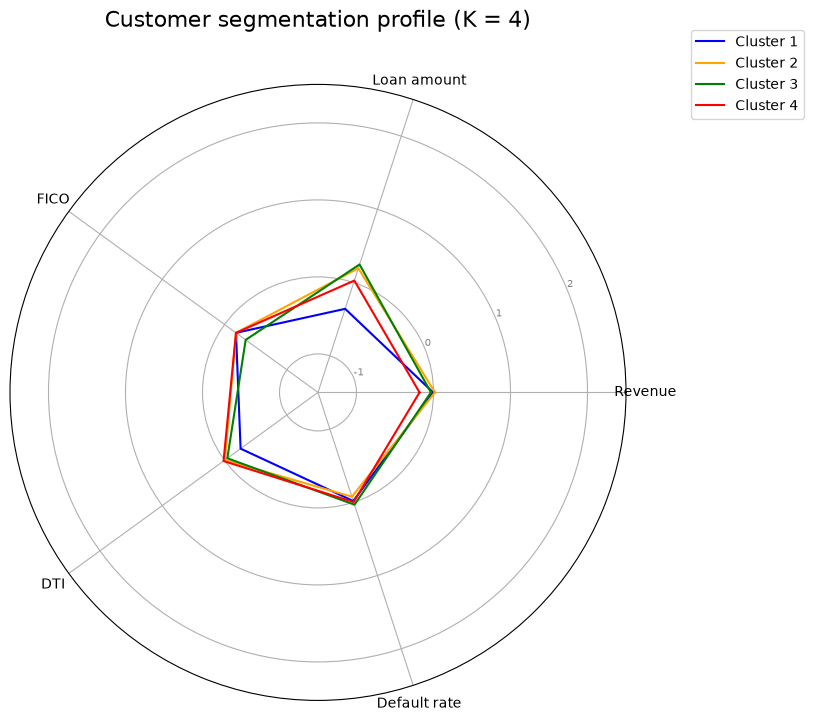

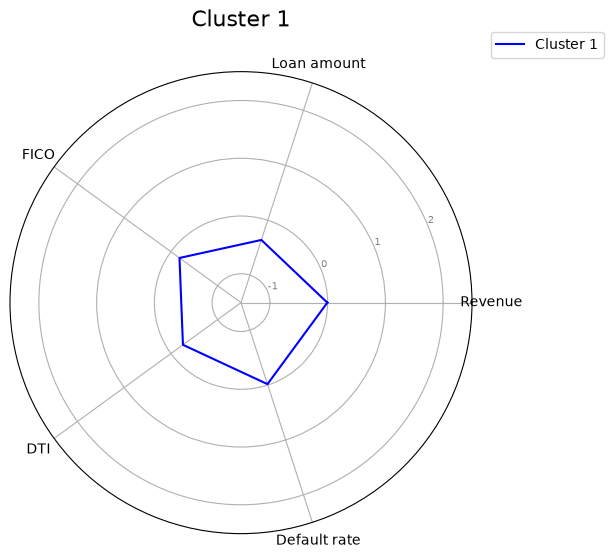

* Cluster 1: 16.9% of sampled borrowers, default rate 20.07% (close to the sample average of 20.74%).
* Noticeably higher than average: none
* Noticeably lower than average: none
* Close to average: Revenue, Loan amount, FICO, DTI, Default rate 



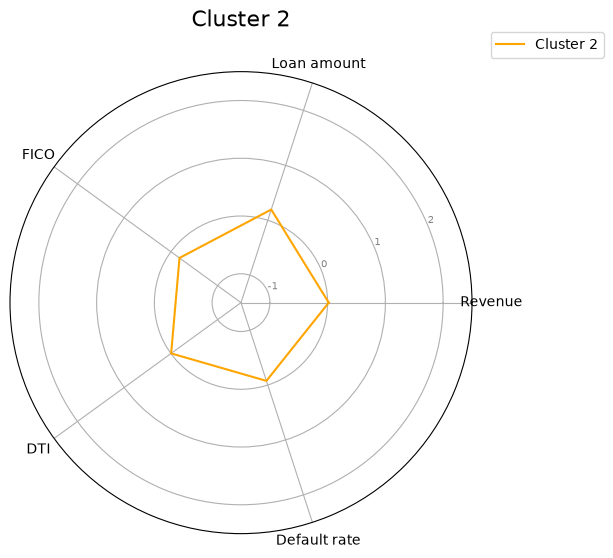

* Cluster 2: 19.4% of sampled borrowers, default rate 17.67% (below the sample average of 20.74%).
* Noticeably higher than average: none
* Noticeably lower than average: none
* Close to average: Revenue, Loan amount, FICO, DTI, Default rate 



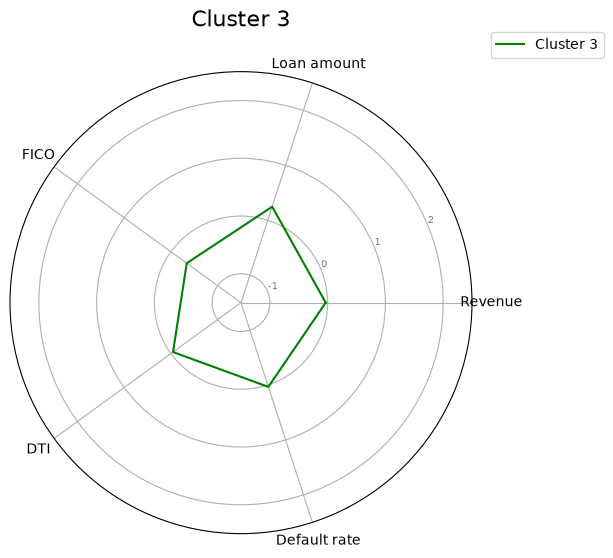

* Cluster 3: 53.1% of sampled borrowers, default rate 22.10% (above the sample average of 20.74%).
* Noticeably higher than average: none
* Noticeably lower than average: none
* Close to average: Revenue, Loan amount, FICO, DTI, Default rate 



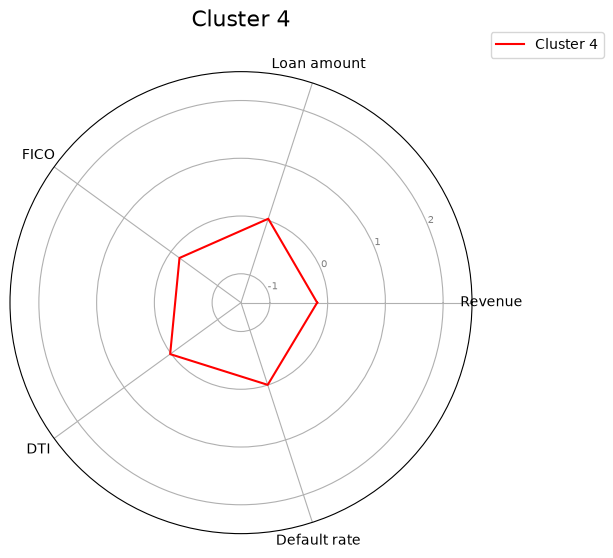

* Cluster 4: 10.6% of sampled borrowers, default rate 20.60% (close to the sample average of 20.74%).
* Noticeably higher than average: none
* Noticeably lower than average: none
* Close to average: Revenue, Loan amount, FICO, DTI, Default rate 



In [47]:
plot_radar(radar_final, f'Customer segmentation profile (K = {FINAL_K})', size=8)

descriptions = {}
overall_rate = default_arr.mean() * 100

for c in radar_final.index:
    plot_radar(radar_final, f'Cluster {c + 1}', clusters=[c], size=6)

    row = radar_final.loc[c, radar_axes]
    row.index = radar_names
    high = row[row >= 0.5].sort_values(ascending=False)
    low = row[row <= -0.5].sort_values()

    rate = default_arr[final_labels == c].mean() * 100
    share = (final_labels == c).mean() * 100
    risk = 'above' if rate > overall_rate + 1 else 'below' if rate < overall_rate - 1 else 'close to'

    lines = [f"* Cluster {c + 1}: {share:.1f}% of sampled borrowers, default rate {rate:.2f}% "
             f"({risk} the sample average of {overall_rate:.2f}%)."]
    lines.append("* Noticeably higher than average: " + (", ".join(f"{k} ({v:+.2f})" for k, v in high.items()) or "none"))
    lines.append("* Noticeably lower than average: " + (", ".join(f"{k} ({v:+.2f})" for k, v in low.items()) or "none"))
    lines.append("* Close to average: " + (", ".join(row.index.difference(list(high.index) + list(low.index))) or "none"))

    descriptions[c] = "\n".join(lines)
    print(descriptions[c], "\n")

### 7.5.8 Number of borrowers in each cluster

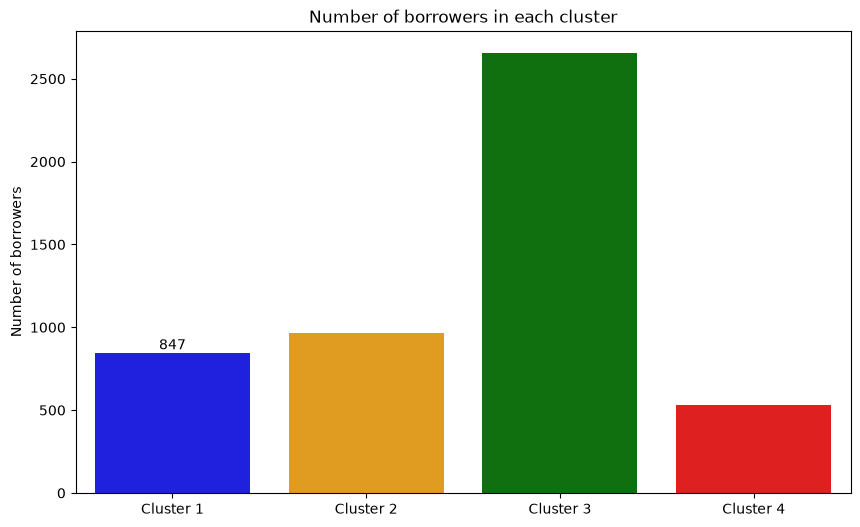

In [48]:
plt.figure(figsize=(10, 6))
ax = sns.countplot(x=pd.Series(final_labels, name='cluster'), hue=pd.Series(final_labels, name='cluster'), palette=palette[:FINAL_K], legend=False)
ax.bar_label(ax.containers[0])
ax.set_xticks(range(FINAL_K))
ax.set_xticklabels([f'Cluster {i + 1}' for i in range(FINAL_K)])
plt.title('Number of borrowers in each cluster')
plt.xlabel('')
plt.ylabel('Number of borrowers')
plt.show()

### 7.5.9 Segment names

As in the airline notebook, each cluster is given a business name. The name below is generated from the cluster's dominant home ownership and loan purpose (which, as noted in Section 7.3, are what mainly separate these clusters) plus its observed default rate relative to the sample average. Rename them manually if you prefer a different wording.

In [49]:
overall_rate = default_arr.mean() * 100
rows = []

for c in range(FINAL_K):
    sub = profile[profile['Cluster'] == c]
    home = sub['home_ownership_n'].value_counts().idxmax()
    purpose = sub['purpose'].value_counts().idxmax()
    rate = sub['Default'].mean() * 100

    if rate >= overall_rate + 1:
        risk = 'Higher-risk'
    elif rate <= overall_rate - 1:
        risk = 'Lower-risk'
    else:
        risk = 'Average-risk'

    rows.append({
        'Cluster': f'Cluster {c + 1}',
        'Segment name': f'{risk}: {home} / {purpose}',
        'Borrowers': len(sub),
        'Default rate %': round(rate, 2),
    })

segment_names = pd.DataFrame(rows)
display(segment_names)

print("Based on the borrower variables used (revenue, loan amount, FICO, DTI, employment length, loan purpose and home ownership), "
      f"the {FINAL_K} clusters are:")
for i, r in segment_names.iterrows():
    print(f"{i + 1}. {r['Cluster']} - {r['Segment name']} ({r['Borrowers']:,} borrowers, default rate {r['Default rate %']}%)")

,Cluster,Segment name,Borrowers,Default rate %
0,Cluster 1,Average-risk: MORTGAGE / home_improvement,847,20.07
1,Cluster 2,Lower-risk: MORTGAGE / credit_card,968,17.67
2,Cluster 3,Higher-risk: MORTGAGE / debt_consolidation,2656,22.10
3,Cluster 4,Average-risk: OWN / debt_consolidation,529,20.60


Based on the borrower variables used (revenue, loan amount, FICO, DTI, employment length, loan purpose and home ownership), the 4 clusters are:
1. Cluster 1 - Average-risk: MORTGAGE / home_improvement (847 borrowers, default rate 20.07%)
2. Cluster 2 - Lower-risk: MORTGAGE / credit_card (968 borrowers, default rate 17.67%)
3. Cluster 3 - Higher-risk: MORTGAGE / debt_consolidation (2,656 borrowers, default rate 22.1%)
4. Cluster 4 - Average-risk: OWN / debt_consolidation (529 borrowers, default rate 20.6%)


### 7.5.10 Note on interpretation

The radar charts use standardized values, so each axis shows how far a cluster's typical borrower is from the sample average, in standard deviations. Because Section 7.3 showed that the clusters are separated mainly by home ownership and loan purpose, the numeric axes (revenue, loan amount, FICO, DTI) may look similar across clusters; the segment names therefore include home ownership and purpose. The segments describe historical patterns in a 5,000-borrower sample; they are not a default-prediction model and do not establish causation.

In [50]:
from sklearn.base import BaseEstimator
import pandas as pd
for k, v in list(globals().items()):
    if k.startswith("_"): continue
    if isinstance(v, BaseEstimator): print("MODEL    :", k, type(v).__name__)
    elif isinstance(v, pd.DataFrame): print("DATAFRAME:", k, v.shape)

DATAFRAME: df (1347681, 16)
DATAFRAME: cluster_df (1347681, 7)
MODEL    : preprocessor ColumnTransformer
MODEL    : ipca IncrementalPCA
MODEL    : kmeans KMeans
DATAFRAME: kmeans_results (7, 3)
MODEL    : kmeans_final KMeans
DATAFRAME: kmeans_analysis (5000, 9)
DATAFRAME: default_comparison (2, 2)
MODEL    : hc AgglomerativeClustering
DATAFRAME: hierarchical_results_df (4, 2)
MODEL    : hc_final AgglomerativeClustering
DATAFRAME: hc_analysis (5000, 9)
DATAFRAME: hc_summary (2, 8)
DATAFRAME: hc_default_comparison (2, 2)
MODEL    : dbscan_scaler StandardScaler
MODEL    : neighbors NearestNeighbors
MODEL    : dbscan_model DBSCAN
DATAFRAME: dbscan_results_df (5, 6)
MODEL    : dbscan_final DBSCAN
DATAFRAME: dbscan_analysis (5000, 9)
DATAFRAME: dbscan_summary (3, 8)
DATAFRAME: dbscan_default_comparison (3, 2)
MODEL    : pca_scaler StandardScaler
DATAFRAME: kmeans_results_std (7, 3)
MODEL    : model KMeans
DATAFRAME: hc_results_std (7, 2)
MODEL    : kmeans_final_std KMeans
MODEL    : hc_final

In [51]:
import pickle
from pathlib import Path

OUT = Path(r"D:\HCL_PROJECTS\Credit Portfolio Segmentation and Risk Pattern Analysis Project-3\Pickle")
OUT.mkdir(exist_ok=True)

models = {
    # preprocessing + dimensionality reduction
    "preprocessor": preprocessor,
    "ipca": ipca,
    "pca_scaler": pca_scaler,
    "dbscan_scaler": dbscan_scaler,
    # clustering models
    "kmeans_final": kmeans_final,
    "kmeans_final_std": kmeans_final_std,
    "final_model": final_model,
    "hc_final": hc_final,
    "hc_final_std": hc_final_std,
    "dbscan_final": dbscan_final,
}

tables = {
    "cluster_df": cluster_df,
    "kmeans_results": kmeans_results,
    "kmeans_results_std": kmeans_results_std,
    "default_comparison": default_comparison,
    "hierarchical_results_df": hierarchical_results_df,
    "hc_summary": hc_summary,
    "hc_default_comparison": hc_default_comparison,
    "dbscan_results_df": dbscan_results_df,
    "dbscan_summary": dbscan_summary,
    "dbscan_default_comparison": dbscan_default_comparison,
    "evaluation_df": evaluation_df,
    "summary": summary,
    "financial_profile": financial_profile,
    "distribution": distribution,
    "stability_results": stability_results,
    "radar_final": radar_final,
    "segment_names": segment_names,
    "final_profile": final_profile,
}

# 1) One bundle file (easiest to load in Streamlit)
bundle = {"models": models, "tables": tables}
with open(OUT / "model_results_step6_9.pkl", "wb") as f:
    pickle.dump(bundle, f)

# 2) Individual files too (optional)
for name, obj in {**models, **tables}.items():
    with open(OUT / f"{name}.pkl", "wb") as f:
        pickle.dump(obj, f)

# 3) Full data with cluster columns (now 16 columns)
df.to_pickle(OUT / "df_with_clusters.pkl")

print("Saved", len(models), "models,", len(tables), "tables and df", df.shape)

Saved 10 models, 18 tables and df (1347681, 16)
